# Two-Stage Hierarchical Drift-Diffusion Model (HDDM) with Adaptive Staircases

This notebook implements a complete simulation, adaptive staircase testing, and parameter recovery pipeline for a **Two-Stage Drift Diffusion Model (TOPDDM)** in a **Temporal Bisection Task**.

---

## ⚡ Adaptive Staircase & Two-Stage Mechanics

1. **Interleaved Adaptive Staircases:** Utilizes dynamic trial difficulty adjustment loaded from external condition files (`condicoes_teste14.csv`) to track participant psychometric thresholds.
2. **Two-Stage Evidence Accumulation:**
   * **Stage 1 (Stimulus Presentation):** Timer accumulator tracks stimulus duration.
   * **Stage 2 (Post-Offset Decision):** Drift rate dynamically scales based on the offset state $x_{\text{offset}}$ relative to threshold midpoint ($a/2$).
3. **Warm-Up Trimming:** Automatically removes the initial $15\%$ of staircase trials per participant to eliminate transient settling effects prior to HDDM fitting.

---

## 🛠 Pipeline Workflow

1. **Staircase Simulation:** Generates participant-specific trials across adaptive difficulty levels.
2. **Error Response Flipping:** Applies `hddm.utils.flip_errors(data)` to normalize response time distributions for incorrect and correct choices.
3. **Parallel MCMC Sampling:** Runs independent Markov Chain Monte Carlo (MCMC) chains in parallel across CPU cores using `joblib`.
4. **Model Diagnostics & Recovery:** Evaluates DIC model selection, extracts subject-level posterior means, and generates publication-grade KDE density plots, ArviZ-style 94% HDI plots, and comparative forest plots.

---

## 🚀 Key Output Files

| Output File Path | Description |
| :--- | :--- |
| `parameter_recovery_output/staircase_trial_details_trimmed.csv` | Trial-level details with warm-up trials excluded. |
| `parameter_recovery_output/stage2_recovered_parameters.csv` | Summary table of true vs. HDDM recovered subject parameters. |
| `parameter_recovery_output/two_stage_parameter_recovery_scatter_clean.png` | Individual parameter correlation scatter plots with regression lines. |
| `parameter_recovery_output/arviz_style_direct_plot.png` | ArviZ-style posterior KDE overlays with 94% HDI bounds. |
| `parameter_recovery_output/direct_forest_plot.png` | Comparative forest plot of population means and 95% CIs. |

Successfully loaded 2 staircase condition(s) from condicoes_teste14.csv.

Simulation complete! Generated 3910 trials and 50 participant profiles.

Mean Number of trials: 78.2
All outputs saved to: /home/jovyan/work/parameter_recovery_output

1. df_data (Trial-level details - Head 5)
   subj_idx  trial  duration       rt  response staircase  trial_in_staircase   
0         1      1      2.00  0.52397         1     longo                   1  \
1         1      2      0.50  0.68397         1     curto                   1   
2         1      3      0.50  0.51897         0     curto                   2   
3         1      4      1.90  0.82397         0     longo                   2   
4         1      5      1.98  0.52797         1     longo                   3   

   reversal_count  x_offset    drift2  
0               0  0.758680  2.494538  
1               0  0.199840  2.543867  
2               0  0.167224 -2.530410  
3               0  0.720915 -2.498616  
4               1  0.834684  

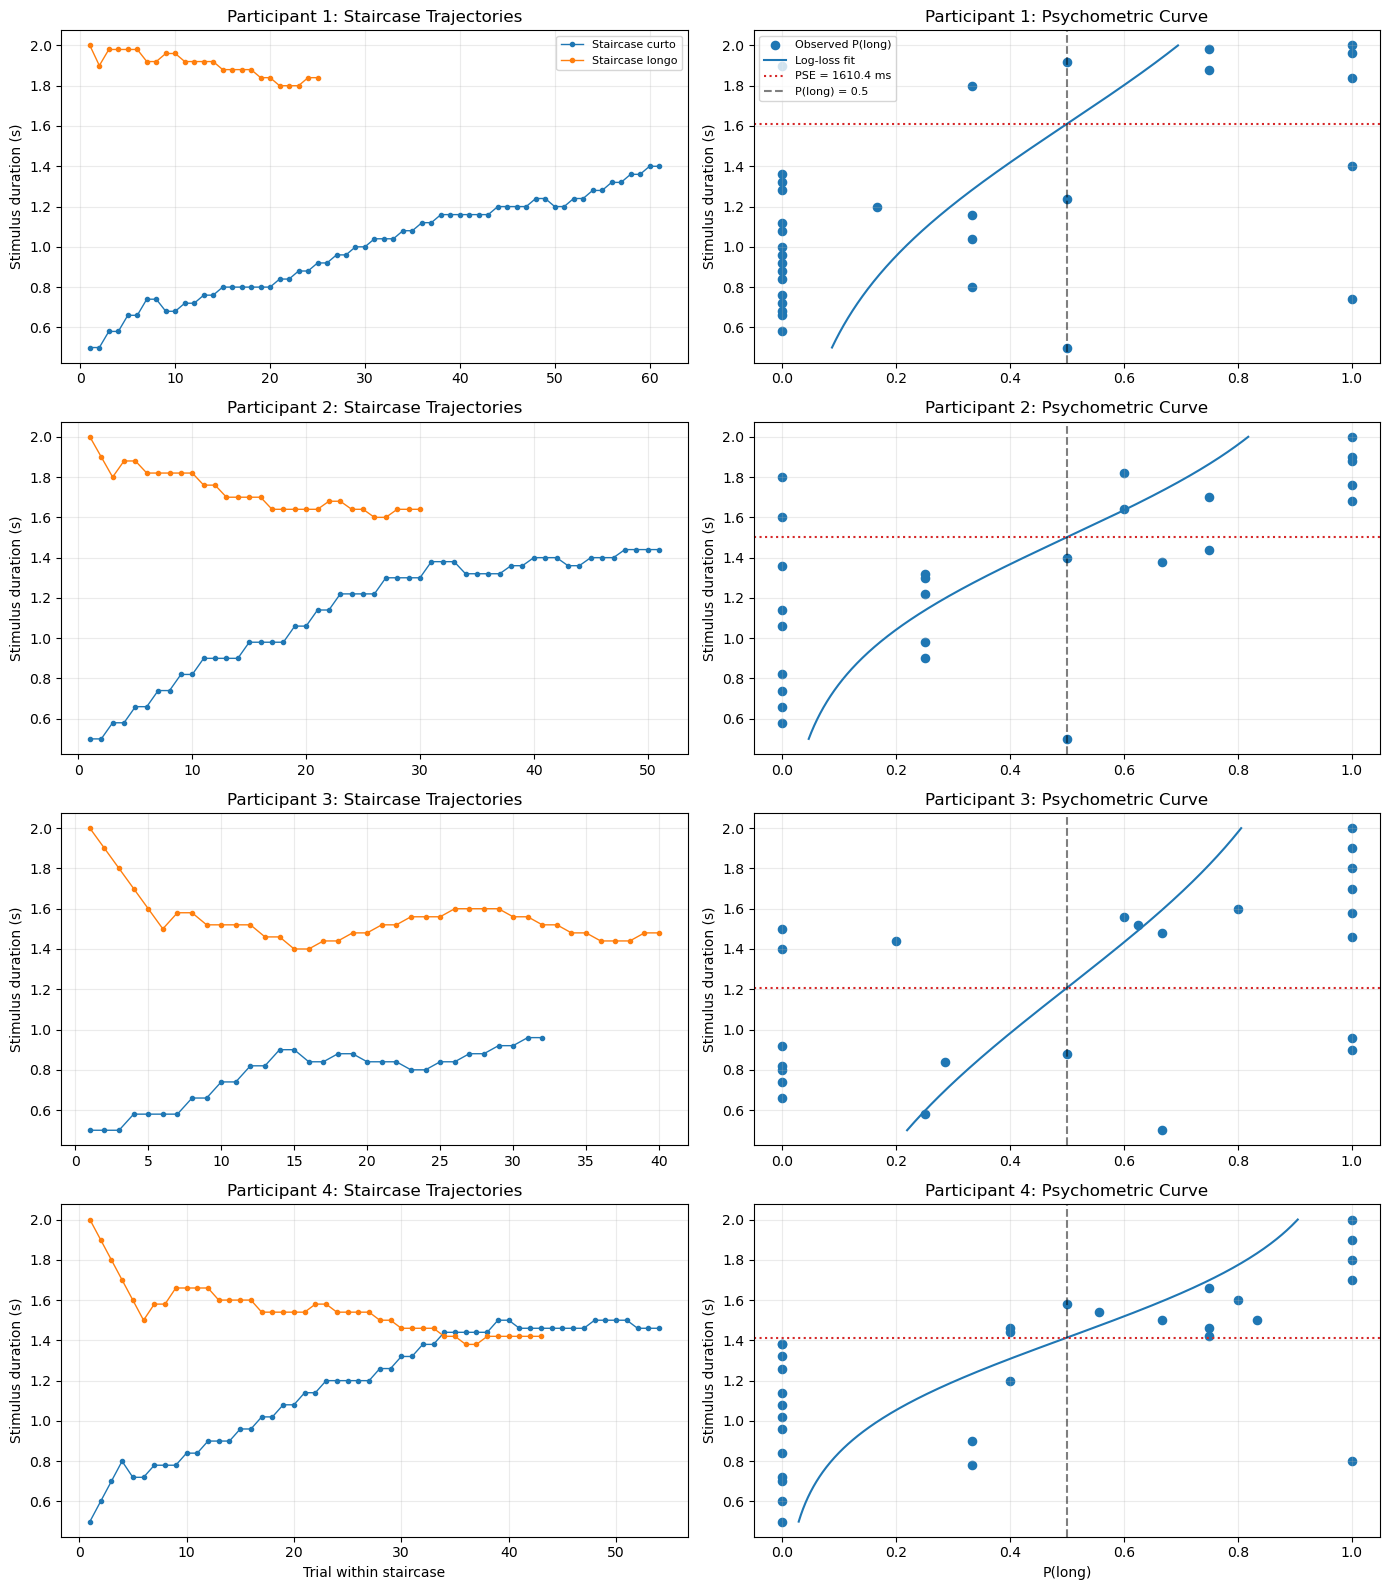


Pooled psychometric metrics
k: 1.6823
x0_seconds: 1.3886
PSE_ms: 1388.6446
T25_ms: 735.6178
T75_ms: 2041.6714
limen_ms: 653.0268
Weber_ratio: 0.4703
log_loss: 0.6385


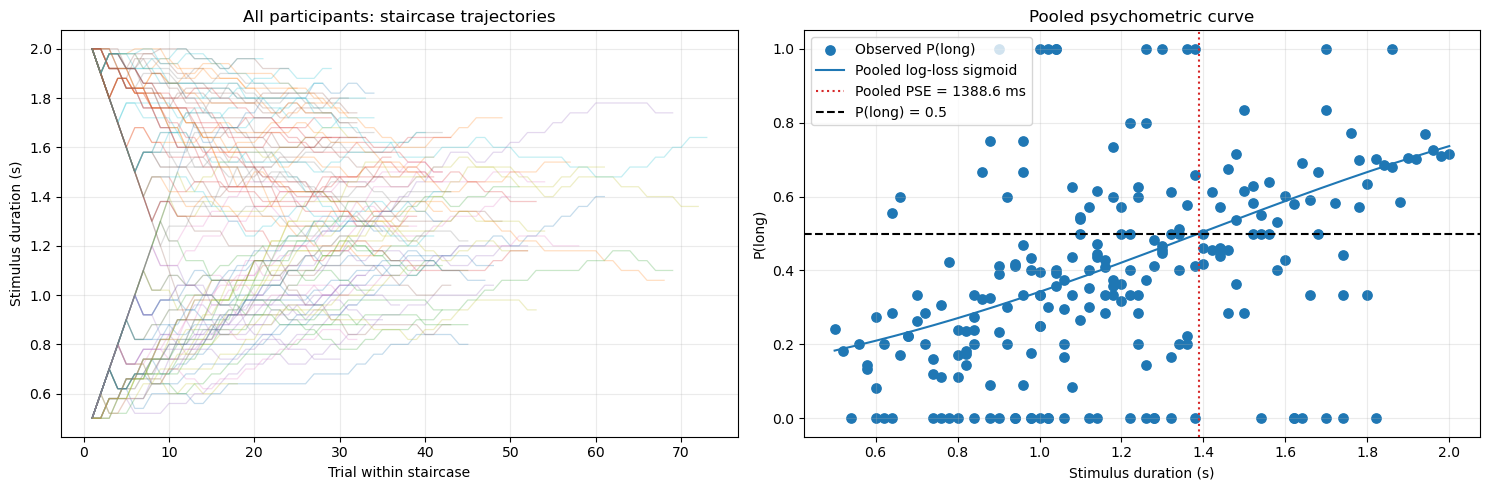


Short response (0)
n = 2096
Mean RT = 0.5977 s
Median RT = 0.5625 s
Inverse Gaussian mu = 0.5977 s
Inverse Gaussian lambda = 0.0273

Long response (1)
n = 1814
Mean RT = 0.6080 s
Median RT = 0.5742 s
Inverse Gaussian mu = 0.6080 s
Inverse Gaussian lambda = 0.0280


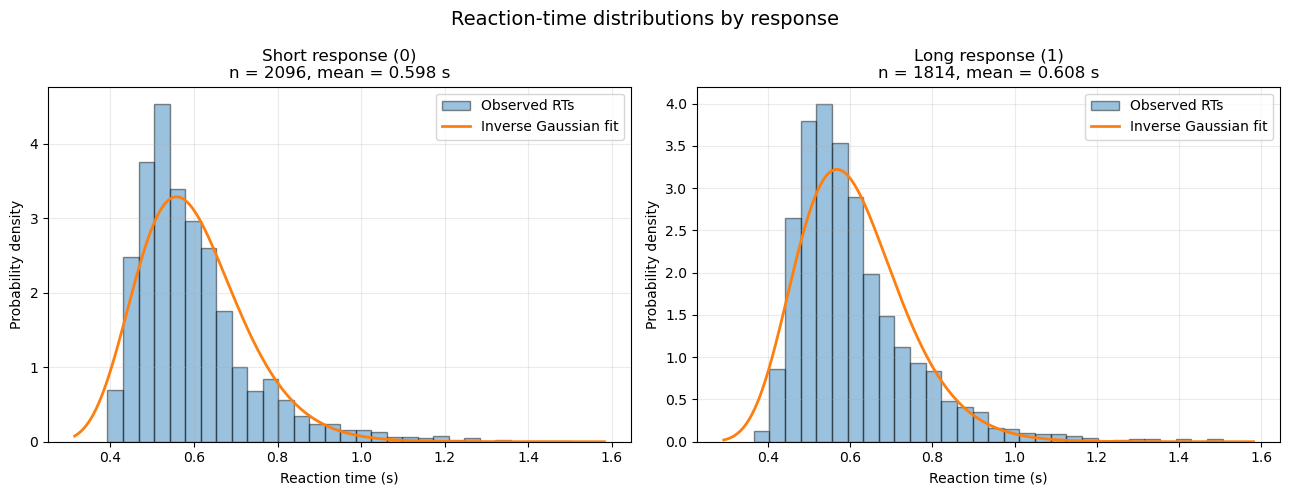


Generating and plotting 4 trajectories choosing from: [1.25]...


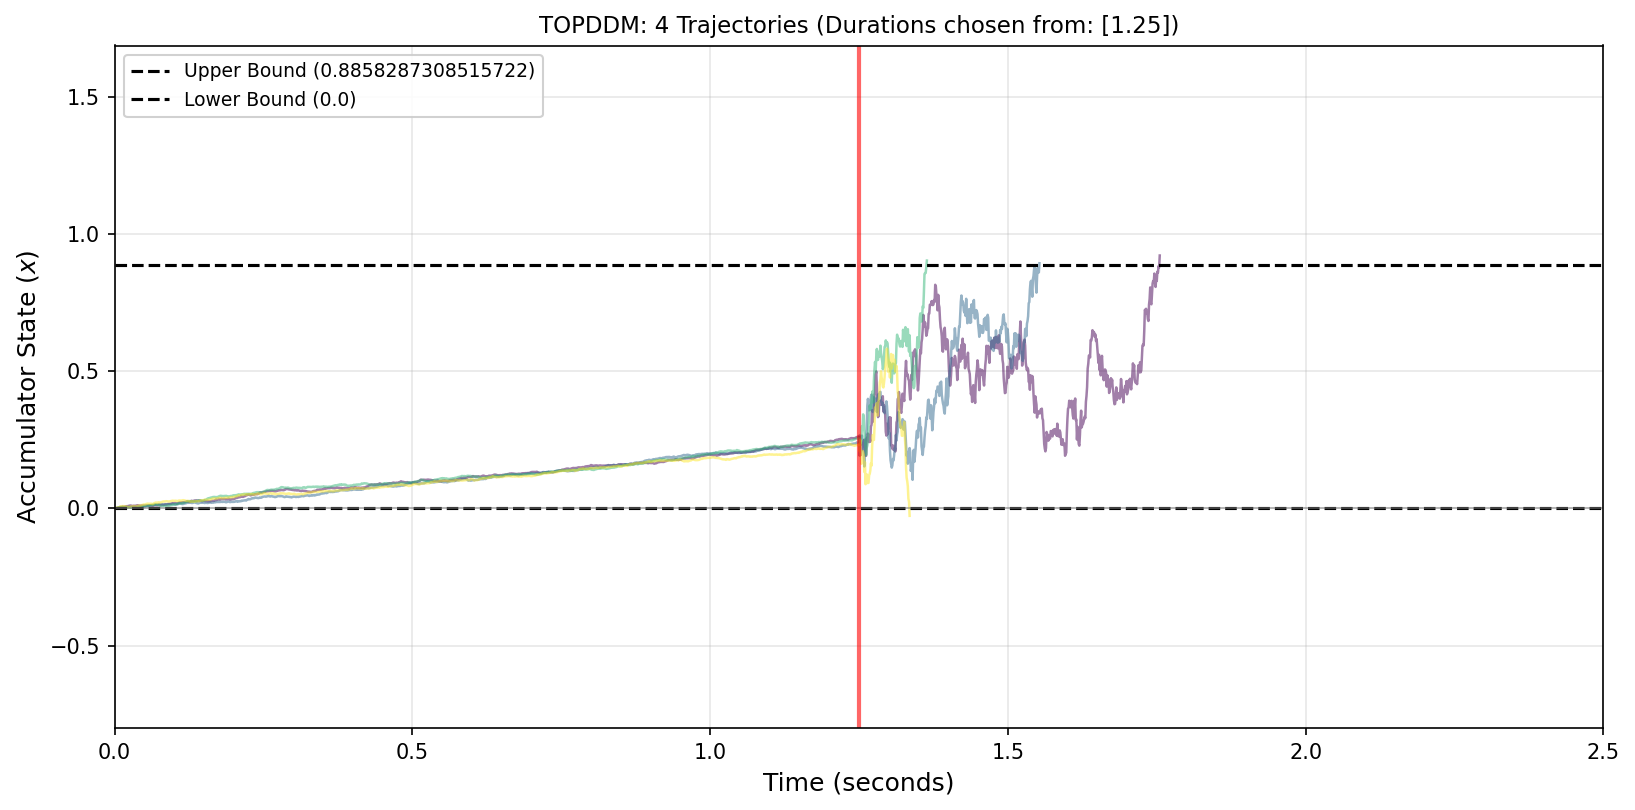

In [10]:
from pathlib import Path
import os
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.stats import invgauss, pearsonr

# ============================================================
# 1. CONFIGURATION & SETUP
# ============================================================

SEED = 20261023
N_PARTICIPANTS = 50

CONDITIONS_FILE = Path("condicoes_teste14.csv")
OUTPUT_DIR = Path("parameter_recovery_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Group-level parameters for the new Two-Stage HDDM bisection model
PARAMS = {
    "a": 0.96,         # Decision threshold mean
    "t": 0.45,        # Non-decision time mean (seconds)
    "v1": 0.87,        # Baseline accumulation rate during stimulus (Stage 1) mean
    "k": 4.88
}

PARAMETER_SD = {
    "a": 0.16,
    "t": 0.05,
    "v1": 0.16,
    "k":0.11
}

# DDM numerical integration settings
DT = 0.001          # Time step (1 ms)
MAX_DECISION_TIME = 5.0
S_NOISE = 1.0       # Diffusion coefficient

USE_RANDOM_EFFECTS = True

# ============================================================
# 2. LOAD STAIRCASE CONDITIONS FROM CSV (Semicolon delimited)
# ============================================================

if not CONDITIONS_FILE.exists():
    raise FileNotFoundError(f"File {CONDITIONS_FILE} not found in current directory.")

conditions_df = pd.read_csv(CONDITIONS_FILE, sep=";")
staircase_conditions = []

required_cols = ["label", "startVal", "minVal", "maxVal", "nUp", "nDown", "nReversals", "stepSizes"]
for col in required_cols:
    if col not in conditions_df.columns:
        raise ValueError(f"Missing required column '{col}' in conditions CSV.")

for _, row in conditions_df.iterrows():
    step_sizes_raw = row["stepSizes"]
    if isinstance(step_sizes_raw, str):
        try:
            step_sizes = ast.literal_eval(step_sizes_raw)
        except (ValueError, SyntaxError):
            step_sizes = [float(x.strip()) for x in step_sizes_raw.replace("[", "").replace("]", "").split(",")]
    else:
        step_sizes = list(step_sizes_raw)

    condition = {
        "label": str(row["label"]),
        "start": float(row["startVal"]),
        "minimum": float(row["minVal"]),
        "maximum": float(row["maxVal"]),
        "n_up": int(row["nUp"]),
        "n_down": int(row["nDown"]),
        "n_reversals": int(row["nReversals"]),
        "step_sizes": [abs(s) for s in step_sizes]
    }
    staircase_conditions.append(condition)

print(f"Successfully loaded {len(staircase_conditions)} staircase condition(s) from {CONDITIONS_FILE.name}.")

# ============================================================
# 3. GENERATE PARTICIPANT PARAMETERS
# ============================================================

rng = np.random.default_rng(SEED)

def make_participant_parameters():
    """Generate known parameters for one participant."""
    p = PARAMS.copy()

    if USE_RANDOM_EFFECTS:
        p["a"] = max(0.1, np.random.normal(PARAMS["a"], PARAMETER_SD["a"]))
        p["t"] = max(0.05, np.random.normal(PARAMS["t"], PARAMETER_SD["t"]))
        p["v1"] = max(0.0, np.random.normal(PARAMS["v1"], PARAMETER_SD["v1"]))
        p["k"] = max(0.0, np.random.normal(PARAMS["k"], PARAMETER_SD["k"]))

    return p

participant_parameters = {
    subj_idx: make_participant_parameters()
    for subj_idx in range(1, N_PARTICIPANTS + 1)
}

assert PARAMS["a"] > 0
assert PARAMS["t"] >= 0

# ============================================================
# 4. TWO-STAGE TOPDDM TRIAL SIMULATOR
# ============================================================

def simulate_topddm_trial_v2(duration, params, return_trajectory=True):
    """
    Two-stage trial simulator using the new bisection drift and bounding mechanics.
    """
    dt = DT
    max_t = MAX_DECISION_TIME
    s = S_NOISE

    subj_a = params["a"]
    subj_t = params["t"]
    subj_v1 = params["v1"]
    subj_k = params["k"]

    upper_bound = subj_a
    lower_bound = 0.0

    target = 2.0
    gamma = 0.2

    I_current = (subj_a / target) * subj_v1
    drift = I_current - (gamma * I_current)
    dcoeff = np.sqrt(I_current + (I_current * gamma)) * 0.1

    # ========================================================
    # STAGE 1: TIMER ACCUMULATOR (During Stimulus Presentation)
    # ========================================================
    current_time = 0.0
    stage1_elapsed = 0.0
    x1 = 0.0

    traj1 = [0.0]
    terminated_in_stage1 = False

    while stage1_elapsed < duration:
        x1 += drift * dt + np.sqrt(dt) * np.sqrt(drift) * dcoeff * np.random.normal(0, 1)
        current_time += dt
        stage1_elapsed += dt

        if x1 < 0:
            x1 = -x1

        traj1.append(x1)

        if x1 >= upper_bound:
            terminated_in_stage1 = True
            break

    if terminated_in_stage1:
        response = 1
        decision = "Long"
        decision_time = 0.0
        rt = subj_t

        if not return_trajectory:
            return response, rt

        return response, rt, {
            "traj1": np.array(traj1),
            "traj2": np.array([]),
            "time_at_offset": current_time,
            "decision": decision,
            "decision_time": decision_time,
            "rt": rt,
            "response": response,
            "estimated_duration": x1,
            "drift1": drift,
            "drift2": None,
            "hit": "upper",
            "crossed_upper_during_stimulus": True,
            "crossing_time": current_time,
        }

    x_at_offset = x1
    x2 = x_at_offset
    stage2_elapsed = 0.0

    # ========================================================
    # STAGE 2: DECISION ACCUMULATOR (After Stimulus Offset)
    # ========================================================
    k = subj_k
    traj2 = [x2]
    hit = None
    decision_time = max_t

    while current_time < max_t:
        v_stage2 = k * (x2 - subj_a / 2.0)
        
        x2 += v_stage2 * dt + np.sqrt(dt) * s * np.random.normal(0, 1)
        current_time += dt
        stage2_elapsed += dt

        traj2.append(x2)

        if x2 >= upper_bound:
            hit = "upper"
            decision_time = stage2_elapsed
            break
        elif x2 <= lower_bound:
            hit = "lower"
            decision_time = stage2_elapsed
            break

    if hit == "upper":
        response = 1
        decision = "Long"
    elif hit == "lower":
        response = 0
        decision = "Short"
    else:
        response = int(x2 >= subj_a / 2.0)
        decision = "Long" if response == 1 else "Short"

    rt = decision_time + subj_t

    if not return_trajectory:
        return response, rt

    return response, rt, {
        "traj1": np.array(traj1),
        "traj2": np.array(traj2),
        "time_at_offset": duration,
        "decision": decision,
        "decision_time": decision_time,
        "rt": rt,
        "response": response,
        "estimated_duration": x_at_offset,
        "drift1": drift,
        "drift2": v_stage2,
        "hit": hit,
        "crossed_upper_during_stimulus": False,
        "crossing_time": None,
    }

# ============================================================
# 5. INTERLEAVED ADAPTIVE STAIRCASES & PARTICIPANT SIMULATION
# ============================================================

def initialize_staircase(condition):
    return {
        "condition": condition,
        "duration": float(condition["start"]),
        "previous_direction": None,
        "consecutive_long": 0,
        "consecutive_short": 0,
        "reversal_count": 0,
        "trial_in_staircase": 0,
        "active": True,
    }


def run_staircase_trial(subj_idx, staircase, params, global_trial, tracking_dicts):
    condition = staircase["condition"]
    duration = staircase["duration"]

    n_up = condition["n_up"]
    n_down = condition["n_down"]
    step_sizes = condition["step_sizes"]
    minimum = condition["minimum"]
    maximum = condition["maximum"]
    n_reversals_target = condition["n_reversals"]

    response, rt, trajectory = simulate_topddm_trial_v2(
        duration, params, return_trajectory=True
    )

    all_trajectories.append({
        "subj_idx": subj_idx,
        "trial": global_trial,
        "duration": float(duration),
        "staircase": condition["label"],
        **trajectory,
    })
    staircase["trial_in_staircase"] += 1

    x_offset = trajectory["estimated_duration"]
    drift2 = trajectory["drift2"]
    
    tracking_dicts["z2_trials"].append(x_offset)
    if drift2 is not None:
        if x_offset < (params["a"] / 2.0):
            tracking_dicts["short_v2"].append(drift2)
        else:
            tracking_dicts["long_v2"].append(drift2)

    trial_record = {
        "subj_idx": subj_idx,
        "trial": global_trial,
        "duration": float(duration),
        "rt": float(rt),
        "response": int(response),
        "staircase": condition["label"],
        "trial_in_staircase": staircase["trial_in_staircase"],
        "reversal_count": staircase["reversal_count"],
        "x_offset": x_offset,
        "drift2": drift2
    }

    direction = None
    if staircase["reversal_count"] == 0:
        direction = -1 if response == 1 else 1
    else:
        if response == 1:
            staircase["consecutive_long"] += 1
            staircase["consecutive_short"] = 0
        else:
            staircase["consecutive_short"] += 1
            staircase["consecutive_long"] = 0

        if staircase["consecutive_long"] >= n_up:
            direction = -1
        elif staircase["consecutive_short"] >= n_down:
            direction = 1

    if direction is None:
        return trial_record

    staircase["consecutive_long"] = 0
    staircase["consecutive_short"] = 0

    previous_direction = staircase["previous_direction"]
    if previous_direction is not None and direction != previous_direction:
        staircase["reversal_count"] += 1

    if staircase["reversal_count"] >= n_reversals_target:
        staircase["active"] = False
        return trial_record

    staircase["previous_direction"] = direction

    step_index = min(staircase["reversal_count"], len(step_sizes) - 1)
    step = float(step_sizes[step_index])

    staircase["duration"] = float(np.clip(
        duration + direction * step,
        minimum,
        maximum
    ))

    return trial_record


def run_participant_simulation(subj_idx, conditions, params):
    staircases = [initialize_staircase(c) for c in conditions]
    trial_records = []
    global_trial = 0
    round_number = 0

    tracking_dicts = {
        "short_v2": [],
        "long_v2": [],
        "z2_trials": []
    }

    while any(s["active"] for s in staircases):
        ordered_staircases = staircases if round_number % 2 == 0 else staircases[::-1]
        for staircase in ordered_staircases:
            if not staircase["active"]:
                continue
            global_trial += 1
            record = run_staircase_trial(subj_idx, staircase, params, global_trial, tracking_dicts)
            trial_records.append(record)
        round_number += 1

    return trial_records, tracking_dicts


# ============================================================
# 6. RUN SIMULATION FOR ALL PARTICIPANTS & BUILD DATASETS
# ============================================================

all_trials = []
all_trajectories = []
subject_params = []

for subj in range(1, N_PARTICIPANTS + 1):
    params = participant_parameters[subj]
    participant_trials, tracking = run_participant_simulation(
        subj_idx=subj,
        conditions=staircase_conditions,
        params=params
    )
    all_trials.extend(participant_trials)

    subject_params.append({
        'subj_idx': subj,
        'v_true_short': np.mean(tracking["short_v2"]) if tracking["short_v2"] else np.nan,
        'v_true_long': np.mean(tracking["long_v2"]) if tracking["long_v2"] else np.nan,
        'a_true': params["a"],
        'z2_true': np.mean(tracking["z2_trials"]) if tracking["z2_trials"] else np.nan,
        'mean_z2_normalized': (np.mean(tracking["z2_trials"]) / params["a"]) if tracking["z2_trials"] else np.nan,
        't_true': params["t"]
    })

df_data = pd.DataFrame(all_trials)
df_params = pd.DataFrame(subject_params)

# Export core datasets
df_data.to_csv(OUTPUT_DIR / "staircase_trial_details.csv", index=False)
df_params.to_csv(OUTPUT_DIR / "true_generating_parameters.csv", index=False)

stage2_records = []
for trial_info in all_trajectories:
    subj_idx = trial_info["subj_idx"]
    params = participant_parameters[subj_idx]
    
    a_val = params["a"]
    a2_width = a_val
    raw_estimate = trial_info.get("estimated_duration", None)
    z2_start2 = np.clip(raw_estimate, 0.01, a_val - 0.01)
    z2_relative = z2_start2 / a2_width
    
    stage2_records.append({
        "subj_idx": subj_idx,
        "trial": trial_info["trial"],
        "duration": trial_info["duration"],
        "response": trial_info["response"],
        "rt": trial_info["rt"],
        "z2_start2": z2_start2,
        "z2_relative": z2_relative,
        "v2_drift2": trial_info.get("drift2", 0),
        "a2_boundary_width": a2_width,
        "t2_non_decision": params["t"]
    })

stage2_df = pd.DataFrame(stage2_records)
stage2_df.to_csv(OUTPUT_DIR / "stage2_trial_parameters.csv", index=False)

# Summary metrics
participant_summary = stage2_df.groupby("subj_idx").agg({
    "rt": ["mean", "std", "median"],
    "response": ["mean"],
    "z2_start2": ["mean", "std"],
    "z2_relative": ["mean", "std"],
    "v2_drift2": ["mean", "std"],
    "a2_boundary_width": ["first"],
    "t2_non_decision": ["first"]
})
participant_summary.columns = ['_'.join(col).strip() for col in participant_summary.columns.values]
participant_summary = participant_summary.reset_index()
participant_summary.to_csv(OUTPUT_DIR / "participant_summary_metrics.csv", index=False)

full_sample_summary = stage2_df[[
    "rt", "response", "z2_start2", "z2_relative", "v2_drift2", 
    "a2_boundary_width", "t2_non_decision", "duration"
]].agg(["mean", "std", "median", "min", "max", "count"]).T.reset_index()
full_sample_summary.rename(columns={"index": "variable"}, inplace=True)
full_sample_summary.to_csv(OUTPUT_DIR / "full_sample_summary_metrics.csv", index=False)

print(f"\nSimulation complete! Generated {len(df_data)} trials and {len(df_params)} participant profiles.")
print(f"\nMean Number of trials: {len(df_data)/len(df_params)}")
print(f"All outputs saved to: {OUTPUT_DIR.resolve()}")

# ============================================================
# 7. PRINT GENERATED DATAFRAMES
# ============================================================
print("\n" + "="*50)
print("1. df_data (Trial-level details - Head 5)")
print("="*50)
print(df_data.head())

print("\n" + "="*50)
print("2. df_params (Participant-level true parameters - Head 5)")
print("="*50)
print(df_params.head())

print("\n" + "="*50)
print("3. stage2_df (Stage 2 trial parameters - Head 5)")
print("="*50)
print(stage2_df.head())

print("\n" + "="*50)
print("4. participant_summary (Participant summary metrics - Head 5)")
print("="*50)
print(participant_summary.head())

print("\n" + "="*50)
print("5. full_sample_summary (Full sample summary metrics)")
print("="*50)
print(full_sample_summary.to_string(index=False))

# ============================================================
# 7. PSYCHOMETRIC CURVE: LOG-LOSS SIGMOID FIT
# ============================================================

def sigmoid(x, k, x0):
    return 1 / (1 + np.exp(np.clip(-k * (x - x0), -500, 500)))

def log_loss_fit(params, x, y_true):
    k, x0 = params
    y_pred = sigmoid(x, k, x0)
    y_pred = np.clip(y_pred, 1e-8, 1 - 1e-8)
    return -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

def fit_psychometric_curve(data):
    grouped = (
        data.groupby("duration")["response"]
        .agg(["mean", "count", "sum"])
        .reset_index()
    )

    x = data["duration"].to_numpy(dtype=float)
    y = data["response"].to_numpy(dtype=float)

    if len(np.unique(x)) < 3 or len(np.unique(y)) < 2:
        return grouped, None, None

    initial_params = [5.0, float(np.median(x))]

    result = minimize(
        log_loss_fit,
        x0=initial_params,
        args=(x, y),
        method="L-BFGS-B",
        bounds=[(1e-6, 1e4), (1e-4, 1e2)]
    )

    if not result.success and not np.isfinite(result.fun):
        return grouped, None, None

    k_log, x0_log = result.x

    if k_log <= 0 or not np.isfinite(k_log + x0_log):
        return grouped, None, None

    fitted_loss = log_loss_fit(result.x, x, y)

    pnt_bisec = x0_log * 1000
    T1 = (x0_log - np.log(3) / k_log) * 1000
    T2 = (x0_log + np.log(3) / k_log) * 1000

    lim_dif = (T2 - T1) / 2
    WR = lim_dif / pnt_bisec if pnt_bisec != 0 else np.nan

    metrics = {
        "k": float(k_log),
        "x0_seconds": float(x0_log),
        "PSE_ms": float(pnt_bisec),
        "T25_ms": float(T1),
        "T75_ms": float(T2),
        "limen_ms": float(lim_dif),
        "Weber_ratio": float(WR),
        "log_loss": float(fitted_loss),
    }

    return grouped, result.x, metrics


# ============================================================
# 8. PLOT N PARTICIPANTS IN A SUBPLOT GRID
# ============================================================

def plot_n_participants(N, trials_df):
    """
    Plots staircase trajectories and psychometric curves
    for the first N participants in a structured subplot grid.
    """
    available_ids = sorted(trials_df["subj_idx"].unique())
    max_subj = min(N, len(available_ids))

    if max_subj == 0:
        print("No participant data available to plot.")
        return

    # Create a figure with N rows and 2 columns
    fig, axes = plt.subplots(max_subj, 2, figsize=(14, 4 * max_subj), squeeze=False)

    for idx, subj_idx in enumerate(available_ids[:max_subj]):
        data = trials_df[trials_df["subj_idx"] == subj_idx].copy()
        grouped, fitted, metrics = fit_psychometric_curve(data)

        # --------------------------------------------------------
        # LEFT: Staircase trajectories
        # --------------------------------------------------------
        ax_stair = axes[idx, 0]
        for staircase_id, staircase_data in data.groupby("staircase"):
            x_col = (
                "trial_in_staircase"
                if "trial_in_staircase" in staircase_data.columns
                else "trial"
            )
            staircase_data = staircase_data.sort_values(x_col)

            ax_stair.plot(
                staircase_data[x_col],
                staircase_data["duration"],
                marker="o",
                markersize=3,
                linewidth=1.0,
                label=f"Staircase {staircase_id}"
            )

        ax_stair.set_ylabel("Stimulus duration (s)")
        ax_stair.set_title(f"Participant {subj_idx}: Staircase Trajectories")
        ax_stair.grid(alpha=0.25)
        if idx == 0:
            ax_stair.legend(fontsize=8, loc='upper right')

        # --------------------------------------------------------
        # RIGHT: Psychometric curve
        # --------------------------------------------------------
        ax_psy = axes[idx, 1]
        ax_psy.scatter(
            grouped["mean"],
            grouped["duration"],
            s=35,
            label="Observed P(long)"
        )

        if fitted is not None:
            k_log, x0_log = fitted
            duration_grid = np.linspace(
                data["duration"].min(),
                data["duration"].max(),
                500
            )

            ax_psy.plot(
                sigmoid(duration_grid, k_log, x0_log),
                duration_grid,
                color="tab:blue",
                label="Log-loss fit"
            )

            ax_psy.axhline(
                x0_log,
                linestyle=":",
                color="tab:red",
                label=f"PSE = {x0_log * 1000:.1f} ms"
            )

        ax_psy.axvline(
            0.5,
            linestyle="--",
            color="black",
            alpha=0.5,
            label="P(long) = 0.5"
        )

        ax_psy.set_xlim(-0.05, 1.05)
        ax_psy.set_ylabel("Stimulus duration (s)")
        ax_psy.set_title(f"Participant {subj_idx}: Psychometric Curve")
        ax_psy.grid(alpha=0.25)
        if idx == 0:
            ax_psy.legend(fontsize=8, loc='upper left')

    # Set shared x-labels on the bottom row
    axes[-1, 0].set_xlabel("Trial within staircase")
    axes[-1, 1].set_xlabel("P(long)")

    fig.tight_layout()
    plt.show()

# --- Choose N and run ---
N_participants_to_plot = 4  # <--- Change N here to any number you want!
plot_n_participants(N_participants_to_plot, df_data)
# ============================================================
# 9. POOLED PLOTS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ------------------------------------------------------------
# LEFT: Pooled staircase trajectories
# ------------------------------------------------------------
for (participant, staircase_id), staircase_data in df_data.groupby(
    ["subj_idx", "staircase"]
):
    x_col = (
        "trial_in_staircase"
        if "trial_in_staircase" in staircase_data.columns
        else "trial"
    )

    staircase_data = staircase_data.sort_values(x_col)

    axes[0].plot(
        staircase_data[x_col],
        staircase_data["duration"],
        alpha=0.25,
        linewidth=0.9
    )

axes[0].set_xlabel("Trial within staircase")
axes[0].set_ylabel("Stimulus duration (s)")
axes[0].set_title("All participants: staircase trajectories")
axes[0].grid(alpha=0.25)

# ------------------------------------------------------------
# RIGHT: Pooled psychometric curve
# ------------------------------------------------------------
grouped_all, fitted_all, metrics_all = fit_psychometric_curve(df_data)

axes[1].scatter(
    grouped_all["duration"],
    grouped_all["mean"],
    s=45,
    label="Observed P(long)"
)

if fitted_all is not None:
    k_all, x0_all = fitted_all

    duration_grid = np.linspace(
        df_data["duration"].min(),
        df_data["duration"].max(),
        1000
    )

    axes[1].plot(
        duration_grid,
        sigmoid(duration_grid, k_all, x0_all),
        label="Pooled log-loss sigmoid"
    )

    axes[1].axvline(
        x0_all,
        linestyle=":",
        color="tab:red",
        label=f"Pooled PSE = {x0_all * 1000:.1f} ms"
    )

    print("\nPooled psychometric metrics")
    for name, value in metrics_all.items():
        print(f"{name}: {value:.4f}")

axes[1].axhline(
    0.5,
    linestyle="--",
    color="black",
    label="P(long) = 0.5"
)

axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("Stimulus duration (s)")
axes[1].set_ylabel("P(long)")
axes[1].set_title("Pooled psychometric curve")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()



# ============================================================
# 10. REACTION-TIME DISTRIBUTIONS: INVERSE GAUSSIAN FITS
# ============================================================

rt_data = stage2_df.loc[
    np.isfinite(stage2_df["rt"]) & (stage2_df["rt"] > 0)
].copy()

response_labels = {
    0: "Short response (0)",
    1: "Long response (1)"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for response, ax in zip([0, 1], axes):
    rt = rt_data.loc[
        rt_data["response"] == response, "rt"
    ].to_numpy()

    if len(rt) < 3:
        ax.set_title(f"{response_labels[response]}: insufficient data")
        continue

    shape, loc, scale = invgauss.fit(rt, floc=0)
    x = np.linspace(max(1e-4, rt.min() * 0.8), rt.max() * 1.05, 1000)
    pdf = invgauss.pdf(x, shape, loc=loc, scale=scale)

    ax.hist(
        rt,
        bins=30,
        density=True,
        alpha=0.45,
        edgecolor="black",
        label="Observed RTs"
    )
    ax.plot(x, pdf, linewidth=2, label="Inverse Gaussian fit")

    ax.set_xlabel("Reaction time (s)")
    ax.set_ylabel("Probability density")
    ax.set_title(
        f"{response_labels[response]}\n"
        f"n = {len(rt)}, mean = {rt.mean():.3f} s"
    )
    ax.legend()
    ax.grid(alpha=0.25)

    mu = scale * shape
    lam = scale * shape**2

    print(f"\n{response_labels[response]}")
    print(f"n = {len(rt)}")
    print(f"Mean RT = {rt.mean():.4f} s")
    print(f"Median RT = {np.median(rt):.4f} s")
    print(f"Inverse Gaussian mu = {mu:.4f} s")
    print(f"Inverse Gaussian lambda = {lam:.4f}")

fig.suptitle("Reaction-time distributions by response", fontsize=14)
fig.tight_layout()
plt.show()


# ============================================================
# 11. PLOT N TRIAL TRAJECTORIES WITH SELECTABLE DURATIONS
# ============================================================

def plot_multiple_trial_trajectories(N, params, available_durations=None):
    dt = DT
    a_param = params['a']
    upper_bound = a_param
    lower_bound = 0.0

    if available_durations is None:
        available_durations = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]

    fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
    cmap = plt.colormaps['viridis']

    for i in range(N):
        dur = np.random.choice(available_durations)
        response, rt, trial = simulate_topddm_trial_v2(dur, params, return_trajectory=True)

        traj1 = trial['traj1']
        traj2 = trial['traj2']

        t1 = np.arange(len(traj1)) * dt
        offset_time = trial['time_at_offset']
        t2 = np.arange(len(traj2)) * dt + offset_time

        color = cmap(i / max(1, N - 1))

        ax.plot(t1, traj1, color=color, alpha=0.5, linewidth=1.2)
        if len(traj2) > 1:
            ax.plot(t2, traj2, color=color, alpha=0.5, linewidth=1.2)

    ax.axhline(upper_bound, color='black', linestyle='--', linewidth=1.5, label=f'Upper Bound ({upper_bound})')
    ax.axhline(lower_bound, color='black', linestyle='--', linewidth=1.5, label='Lower Bound (0.0)')
    ax.axhline(0.0, color='gray', linestyle='-', linewidth=0.8, alpha=0.6)
    ax.axvline(available_durations[0], color='red', linestyle='-', linewidth=2, alpha=0.6)

    ax.set_xlabel('Time (seconds)', fontsize=12)
    ax.set_ylabel('Accumulator State ($x$)', fontsize=12)
    ax.set_title(
        f"TOPDDM: {N} Trajectories (Durations chosen from: {available_durations})",
        fontsize=11
    )

    ax.set_xlim(0, 2.5)
    ax.set_ylim(lower_bound - 0.8, upper_bound + 0.8)

    ax.grid(alpha=0.3)
    ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

    fig.tight_layout()
    plt.show()

N_paths = 4
my_chosen_durations = [1.25]
sample_params = participant_parameters[38]

print(f"\nGenerating and plotting {N_paths} trajectories choosing from: {my_chosen_durations}...")
plot_multiple_trial_trajectories(N_paths, sample_params, available_durations=my_chosen_durations)

In [11]:
data = stage2_df
# Categorize duration class for condition-based drift rate fitting
mean_duration = data['duration'].mean()
data['duration_class'] = np.where(data['duration'] < 1.25, 'short', 'long')
data['duration_class'] = data['duration_class'].astype(str)
data

,subj_idx,trial,duration,response,rt,z2_start2,z2_relative,v2_drift2,a2_boundary_width,t2_non_decision,duration_class
0,1,1,2.00,1,0.523970,0.758680,0.717181,2.494538,1.057863,0.506970,long
1,1,2,0.50,1,0.683970,0.199840,0.188909,2.543867,1.057863,0.506970,short
2,1,3,0.50,0,0.518970,0.167224,0.158077,-2.530410,1.057863,0.506970,short
3,1,4,1.90,0,0.823970,0.720915,0.681482,-2.498616,1.057863,0.506970,long
4,1,5,1.98,1,0.527970,0.834684,0.789029,2.551852,1.057863,0.506970,long
...,...,...,...,...,...,...,...,...,...,...,...
3905,50,64,1.08,0,0.558751,0.264244,0.339335,-1.654395,0.778712,0.477751,short
3906,50,65,1.08,0,0.530751,0.262454,0.337036,-1.696923,0.778712,0.477751,short
3907,50,66,1.12,0,0.674751,0.258395,0.331824,-1.647389,0.778712,0.477751,short
3908,50,67,1.12,1,0.610751,0.274408,0.352387,1.700946,0.778712,0.477751,short


In [12]:
# ============================================================
# 7. EXCLUDE INITIAL TRIALS PER PARTICIPANT (WARM-UP / TRIM)
# ============================================================

# Variável de controlo para definir a percentagem de ensaios iniciais a excluir
DROP_PERCENT_EXCLUDE = 15.0  # 15% foi decidido de forma arbritaria ao observar os plots de staircase, o intuito era cortar a faze inicial "facil".

def exclude_initial_trials(df, percent, subj_col='subj_idx', trial_col='trial'):
    """
    Exclui os primeiros x% de ensaios de cada participante com base no número total de ensaios.
    Retorna o DataFrame filtrado e um dicionário com a contagem exata de linhas excluídas por participante.
    """
    excluded_counts = {}
    filtered_groups = []
    
    for subj_idx, group in df.groupby(subj_col):
        # Ordena por número de ensaio para garantir que remove os primeiros cronologicamente
        group_sorted = group.sort_values(by=trial_col)
        n_total = len(group_sorted)
        
        # Calcula quantos ensaios remover (arredondando para cima para garantir pelo menos 1 se aplicável)
        n_to_drop = int(np.ceil(n_total * (percent / 100.0)))
        excluded_counts[subj_idx] = n_to_drop
        
        # Mantém apenas a partir do corte
        filtered_groups.append(group_sorted.iloc[n_to_drop:])
        
    df_filtered = pd.concat(filtered_groups).reset_index(drop=True)
    return df_filtered, excluded_counts

# Aplica a função ao seu DataFrame principal
df_data_trimmed, exclusion_report = exclude_initial_trials(
    data, 
    percent=DROP_PERCENT_EXCLUDE, 
    subj_col='subj_idx', 
    trial_col='trial'
)

# Mostra o relatório de exclusão por participante
print(f"\n--- RELATÓRIO DE ENSAIOS EXCLUÍDOS ({DROP_PERCENT_EXCLUDE}%) ---")
for subj, count in exclusion_report.items():
    print(f"Participante {subj}: {count} ensaios excluídos.")

print(f"\nLinhas antes da exclusão: {len(df_data)}")
print(f"Linhas após a exclusão: {len(df_data_trimmed)}")

# Se necessário, atualize o ficheiro exportado com os dados limpos
df_data_trimmed.to_csv(OUTPUT_DIR / "staircase_trial_details_trimmed.csv", index=False)


--- RELATÓRIO DE ENSAIOS EXCLUÍDOS (15.0%) ---
Participante 1: 13 ensaios excluídos.
Participante 2: 13 ensaios excluídos.
Participante 3: 11 ensaios excluídos.
Participante 4: 15 ensaios excluídos.
Participante 5: 10 ensaios excluídos.
Participante 6: 13 ensaios excluídos.
Participante 7: 11 ensaios excluídos.
Participante 8: 16 ensaios excluídos.
Participante 9: 13 ensaios excluídos.
Participante 10: 15 ensaios excluídos.
Participante 11: 9 ensaios excluídos.
Participante 12: 17 ensaios excluídos.
Participante 13: 11 ensaios excluídos.
Participante 14: 11 ensaios excluídos.
Participante 15: 8 ensaios excluídos.
Participante 16: 10 ensaios excluídos.
Participante 17: 12 ensaios excluídos.
Participante 18: 11 ensaios excluídos.
Participante 19: 9 ensaios excluídos.
Participante 20: 14 ensaios excluídos.
Participante 21: 13 ensaios excluídos.
Participante 22: 15 ensaios excluídos.
Participante 23: 12 ensaios excluídos.
Participante 24: 10 ensaios excluídos.
Participante 25: 16 ensaios 

In [13]:
data = df_data_trimmed
data

,subj_idx,trial,duration,response,rt,z2_start2,z2_relative,v2_drift2,a2_boundary_width,t2_non_decision,duration_class
0,1,14,0.74,1,0.681970,0.281019,0.265648,2.411861,1.057863,0.506970,short
1,1,15,0.74,1,0.595970,0.344900,0.326035,2.334182,1.057863,0.506970,short
2,1,16,1.92,0,0.615970,0.621476,0.587483,-2.535781,1.057863,0.506970,long
3,1,17,1.96,1,0.845970,0.653306,0.617572,2.586680,1.057863,0.506970,long
4,1,18,0.68,0,0.533970,0.250254,0.236565,-2.408251,1.057863,0.506970,short
...,...,...,...,...,...,...,...,...,...,...,...
3295,50,64,1.08,0,0.558751,0.264244,0.339335,-1.654395,0.778712,0.477751,short
3296,50,65,1.08,0,0.530751,0.262454,0.337036,-1.696923,0.778712,0.477751,short
3297,50,66,1.12,0,0.674751,0.258395,0.331824,-1.647389,0.778712,0.477751,short
3298,50,67,1.12,1,0.610751,0.274408,0.352387,1.700946,0.778712,0.477751,short


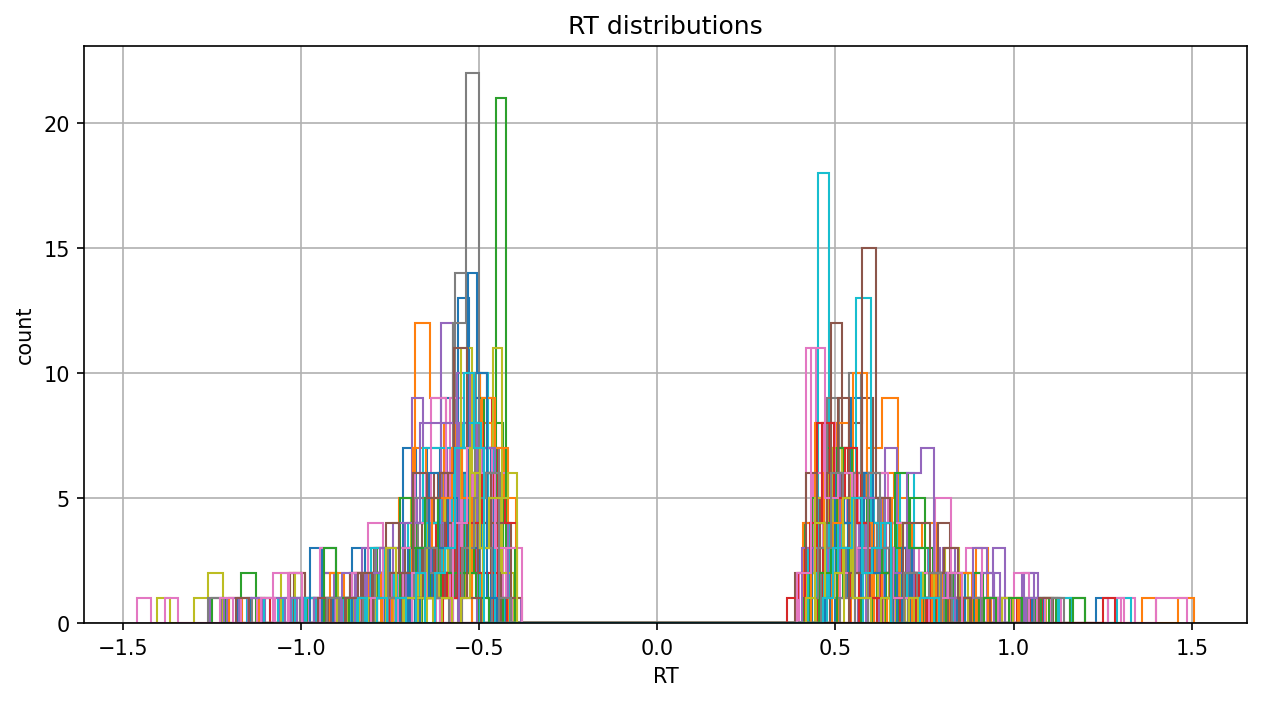

In [14]:
import hddm
data = hddm.utils.flip_errors(data)

fig = plt.figure(figsize=(10,5),dpi=150)
ax = fig.add_subplot(111, xlabel='RT', ylabel='count', title='RT distributions')
for i, subj_data in data.groupby('subj_idx'):
    subj_data.rt.hist(bins=60, histtype='step', ax=ax)

In [15]:
# ============================================================
# 4. FIT HIERARCHICAL HDDM MODEL & DIAGNOSTICS (PARALLELIZED)
# ============================================================
import hddm
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

n_chains = 2
print(f"\nInitializing {n_chains} hierarchical HDDM chains in parallel...")

def fit_single_chain(i, df_data):
    # Set unique seed per chain for MCMC independence
    np.random.seed(40 + i)
    print(f"\n--- Running Chain {i+1} of {n_chains} ---")
    
    m = hddm.HDDM(
        df_data, 
        include=['v', 'a', 't', 'z'], 
        informative=True,
        depends_on={'v': 'duration_class'},
        p_outlier=0.05,
        is_group_model=True
    )
    m.find_starting_values()
    # Slightly optimized sample/burn ratio for speed
    m.sample(5000, burn=1000, dbname=f'traces_chain_{i}.db', db='pickle')
    return m

# Run chains concurrently using all available CPU cores (-1)
models = Parallel(n_jobs=-1)(
    delayed(fit_single_chain)(i, data) for i in range(n_chains)
)

# Model Selection via DIC
print("\n[Model Selection] DIC for all chains:")
dic_values = [m.dic for m in models]
for i, dic_val in enumerate(dic_values):
    print(f"  • Chain {i+1} DIC: {dic_val:.3f}")

best_chain_idx = np.argmin(dic_values)
best_model = models[best_chain_idx]
print(f"\n=> Selecting Chain {best_chain_idx + 1} as primary model (Lowest DIC: {dic_values[best_chain_idx]:.3f})")

# Convergence Check
print("\n[Convergence Diagnostic] Gelman-Rubin Statistics:")
gr_stats = hddm.analyze.gelman_rubin(models)
gr_df = pd.DataFrame.from_dict(gr_stats, orient='index', columns=['R_hat']).sort_values('R_hat', ascending=False)
print(gr_df.head(15))

model = best_model 


Initializing 2 hierarchical HDDM chains in parallel...


/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)
/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)



--- Running Chain 2 of 2 ---
No model attribute --> setting up standard HDDM
Set model to ddm
[                  0%                  ] 8 of 5000 complete in 0.5 sec
[                  0%                  ] 16 of 5000 complete in 1.1 sec
[                  0%                  ] 24 of 5000 complete in 1.6 sec
[                  0%                  ] 32 of 5000 complete in 2.2 sec
[                  0%                  ] 40 of 5000 complete in 2.7 sec
[                  0%                  ] 48 of 5000 complete in 3.2 sec
[                  1%                  ] 56 of 5000 complete in 3.8 sec
[                  1%                  ] 64 of 5000 complete in 4.3 sec
[                  1%                  ] 72 of 5000 complete in 4.9 sec
[                  1%                  ] 80 of 5000 complete in 5.4 sec
[                  1%                  ] 88 of 5000 complete in 5.9 sec
[                  1%                  ] 96 of 5000 complete in 6.5 sec
[                  2%                  ] 1

[------           17%                  ] 880 of 5000 complete in 60.0 sec
[------           17%                  ] 888 of 5000 complete in 60.6 sec
[------           17%                  ] 896 of 5000 complete in 61.1 sec
[------           18%                  ] 904 of 5000 complete in 61.7 sec
[------           18%                  ] 912 of 5000 complete in 62.2 sec
[------           18%                  ] 920 of 5000 complete in 62.8 sec
[-------          18%                  ] 928 of 5000 complete in 63.3 sec
[-------          18%                  ] 936 of 5000 complete in 63.9 sec
[-------          18%                  ] 944 of 5000 complete in 64.4 sec
[-------          19%                  ] 952 of 5000 complete in 65.0 sec
[-------          19%                  ] 960 of 5000 complete in 65.5 sec
[-------          19%                  ] 968 of 5000 complete in 66.1 sec
[-------          19%                  ] 976 of 5000 complete in 66.6 sec
[-------          19%                 

[-------------    34%                  ] 1741 of 5000 complete in 119.2 sec
[-------------    34%                  ] 1749 of 5000 complete in 119.7 sec
[-------------    35%                  ] 1757 of 5000 complete in 120.3 sec
[-------------    35%                  ] 1765 of 5000 complete in 120.9 sec
[-------------    35%                  ] 1773 of 5000 complete in 121.4 sec
[-------------    35%                  ] 1781 of 5000 complete in 121.9 sec
[-------------    35%                  ] 1789 of 5000 complete in 122.5 sec
[-------------    35%                  ] 1797 of 5000 complete in 123.0 sec
[-------------    36%                  ] 1805 of 5000 complete in 123.6 sec
[-------------    36%                  ] 1813 of 5000 complete in 124.1 sec
[-------------    36%                  ] 1821 of 5000 complete in 124.7 sec
[-------------    36%                  ] 1829 of 5000 complete in 125.3 sec
[-------------    36%                  ] 1836 of 5000 complete in 125.8 sec
[-----------

[-----------------51%                  ] 2585 of 5000 complete in 177.7 sec
[-----------------51%                  ] 2593 of 5000 complete in 178.2 sec
[-----------------52%                  ] 2601 of 5000 complete in 178.8 sec
[-----------------52%                  ] 2609 of 5000 complete in 179.3 sec
[-----------------52%                  ] 2617 of 5000 complete in 179.9 sec
[-----------------52%                  ] 2625 of 5000 complete in 180.4 sec
[-----------------52%                  ] 2633 of 5000 complete in 181.0 sec
[-----------------52%                  ] 2641 of 5000 complete in 181.6 sec
[-----------------52%                  ] 2648 of 5000 complete in 182.1 sec
[-----------------53%                  ] 2655 of 5000 complete in 182.6 sec
[-----------------53%                  ] 2662 of 5000 complete in 183.1 sec
[-----------------53%                  ] 2669 of 5000 complete in 183.6 sec
[-----------------53%                  ] 2676 of 5000 complete in 184.1 sec
[-----------

[-----------------68%-----             ] 3416 of 5000 complete in 235.8 sec
[-----------------68%------            ] 3424 of 5000 complete in 236.4 sec
[-----------------68%------            ] 3432 of 5000 complete in 237.0 sec
[-----------------68%------            ] 3440 of 5000 complete in 237.5 sec
[-----------------68%------            ] 3448 of 5000 complete in 238.1 sec
[-----------------69%------            ] 3456 of 5000 complete in 238.6 sec
[-----------------69%------            ] 3463 of 5000 complete in 239.1 sec
[-----------------69%------            ] 3471 of 5000 complete in 239.7 sec
[-----------------69%------            ] 3479 of 5000 complete in 240.3 sec
[-----------------69%------            ] 3487 of 5000 complete in 240.8 sec
[-----------------69%------            ] 3495 of 5000 complete in 241.4 sec
[-----------------70%------            ] 3503 of 5000 complete in 242.0 sec
[-----------------70%------            ] 3510 of 5000 complete in 242.5 sec
[-----------


[Model Selection] DIC for all chains:
  • Chain 1 DIC: -1862.639
  • Chain 2 DIC: -1863.153

=> Selecting Chain 2 as primary model (Lowest DIC: -1863.153)

[Convergence Diagnostic] Gelman-Rubin Statistics:
                     R_hat
t_subj.33         1.003006
a_subj.33         1.002840
z_std             1.002576
z_subj_trans.26   1.002569
v_subj(short).37  1.002076
t_subj.44         1.002053
a_subj.4          1.001972
t_subj.7          1.001782
z_subj_trans.23   1.001690
t_subj.4          1.001687
z_subj_trans.49   1.001632
t_subj.26         1.001436
t_subj.42         1.001427
z_subj_trans.36   1.001385
v_subj(long).26   1.001378


Plotting a
Plotting a_std
Plotting v(long)
Plotting v(short)
Plotting v_std
Plotting t
Plotting t_std
Plotting z
Plotting z_std


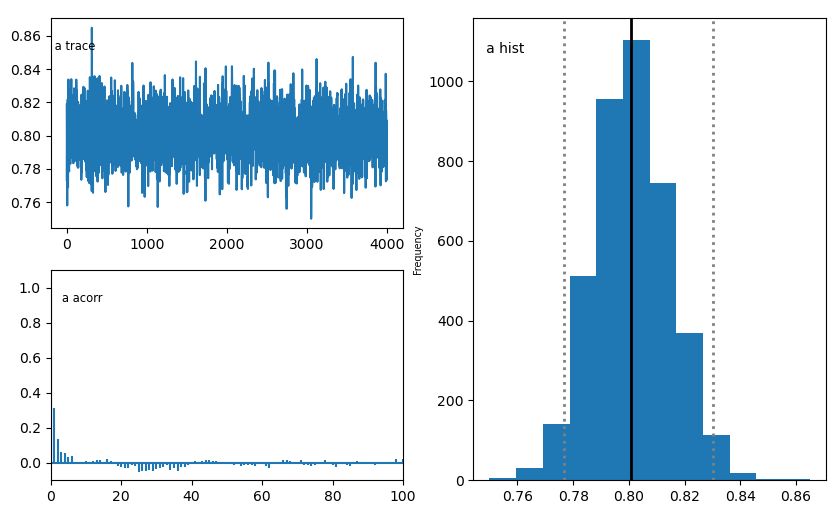

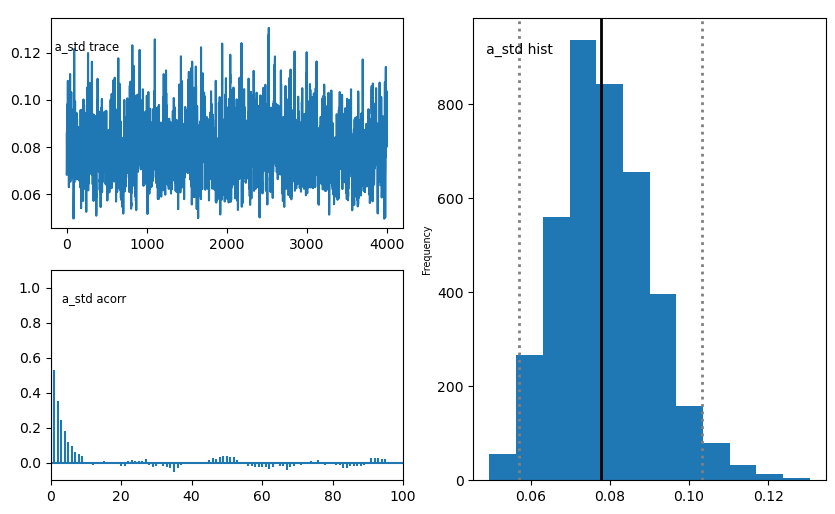

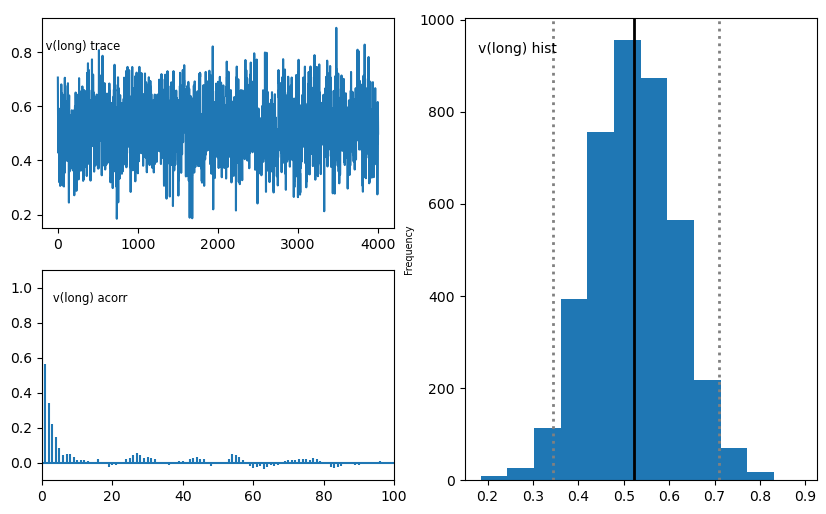

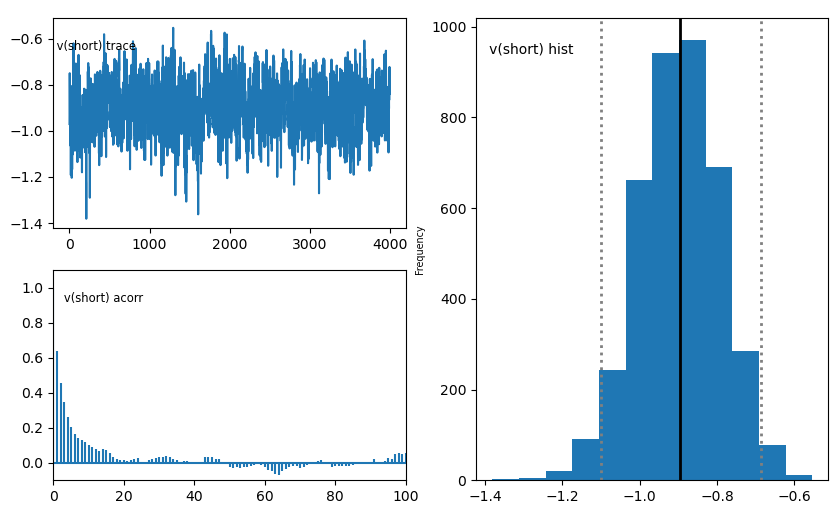

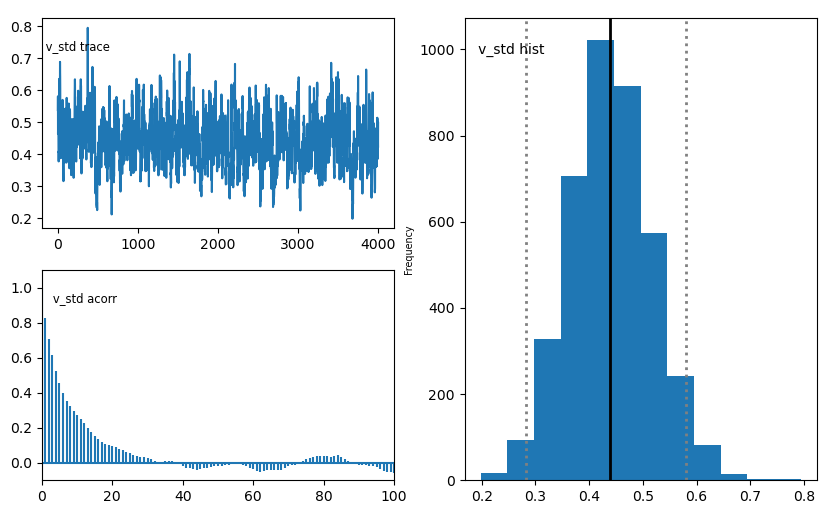

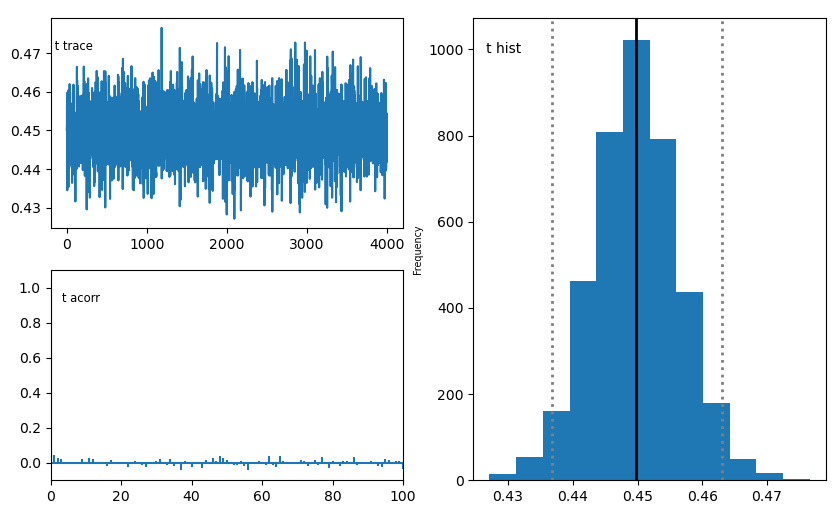

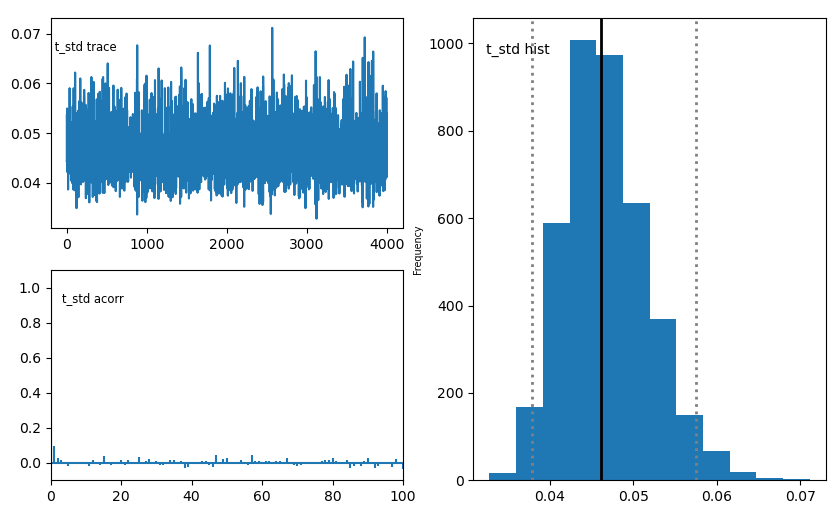

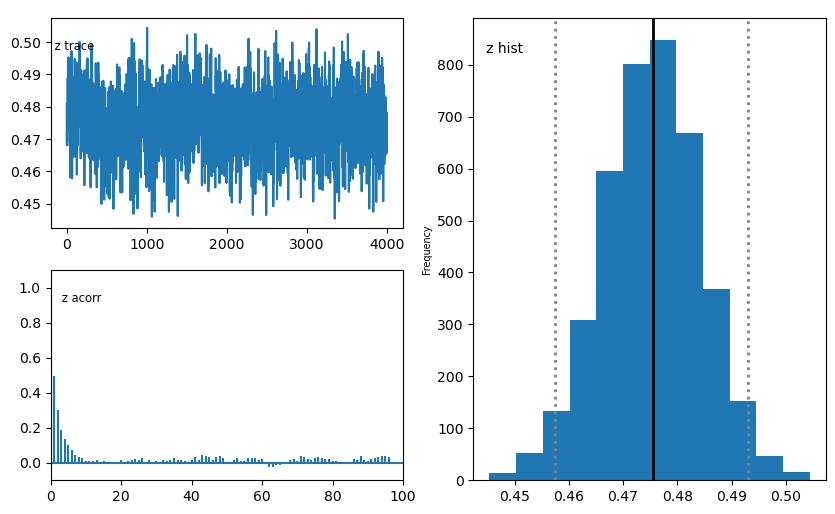

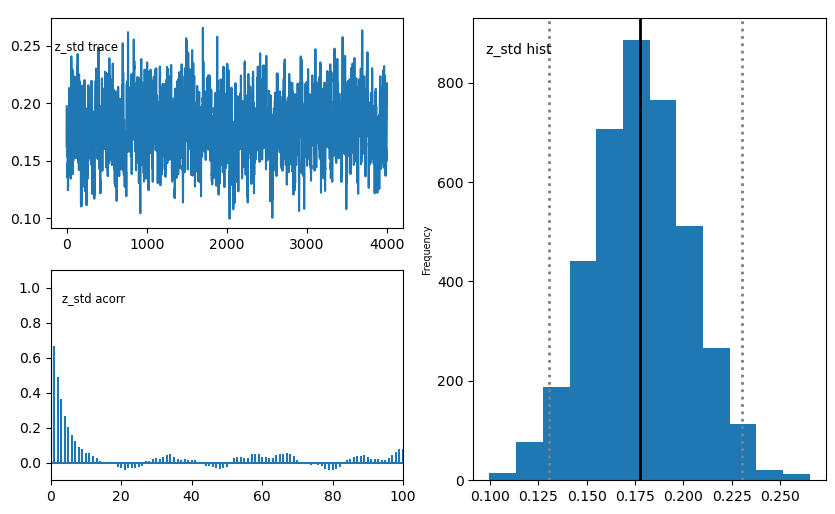

In [16]:
best_model.plot_posteriors()


Parâmetros recuperados guardados com sucesso em 'parameter_recovery_output/stage2_recovered_parameters.csv'!


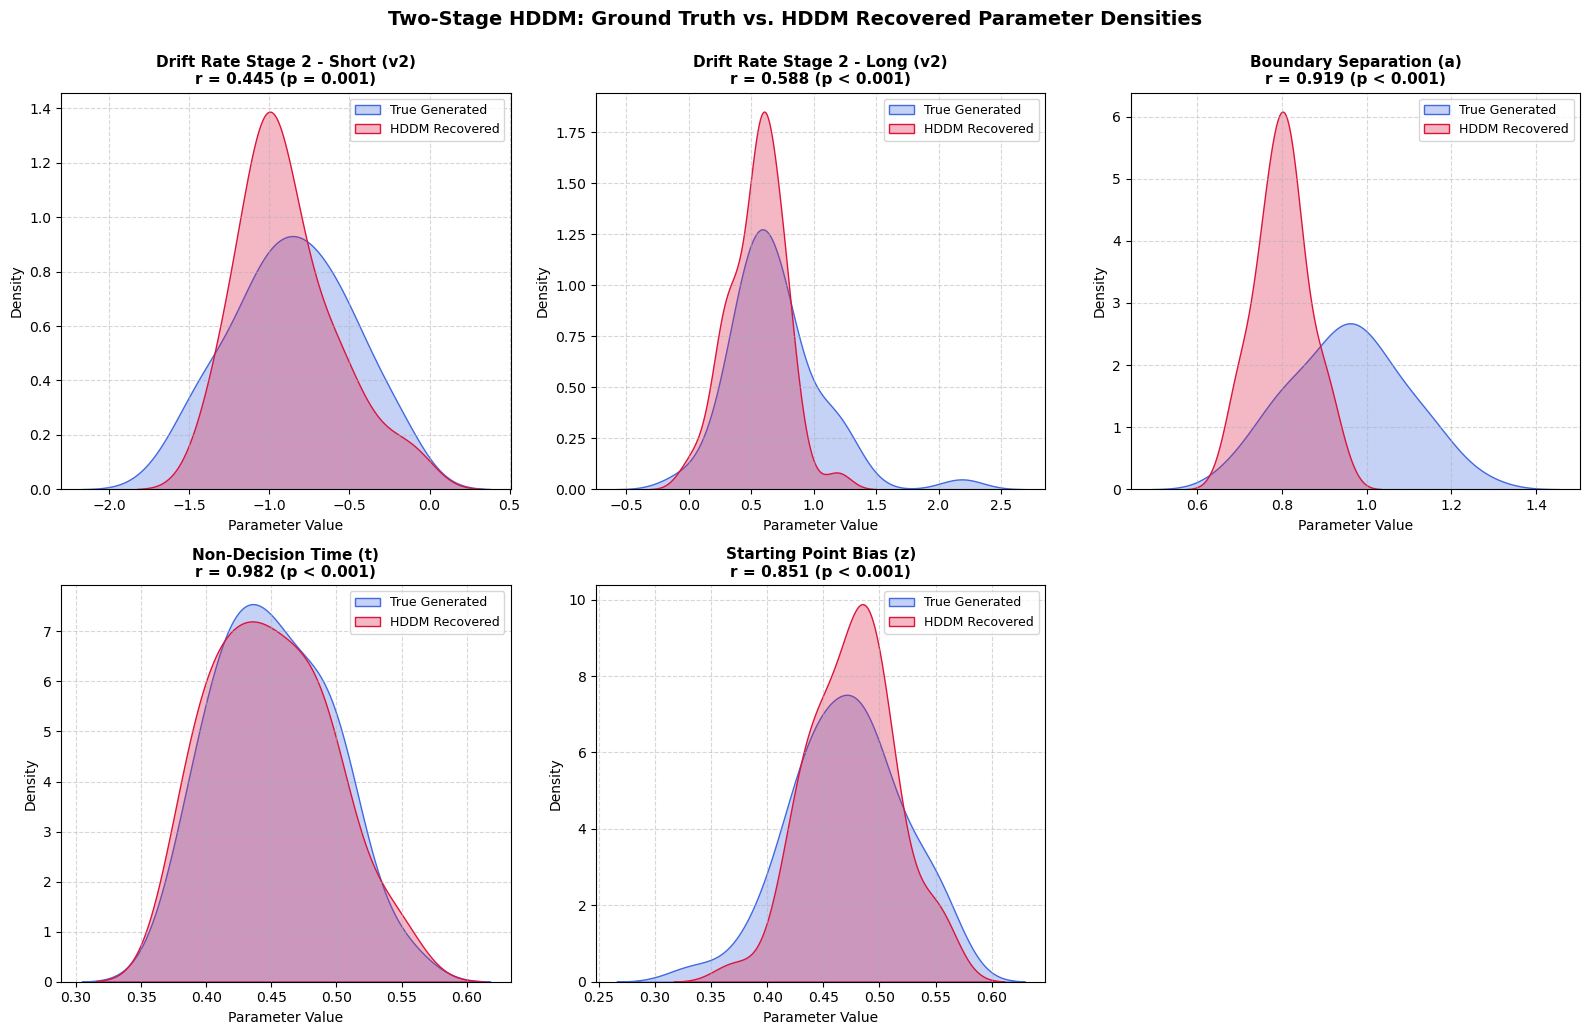

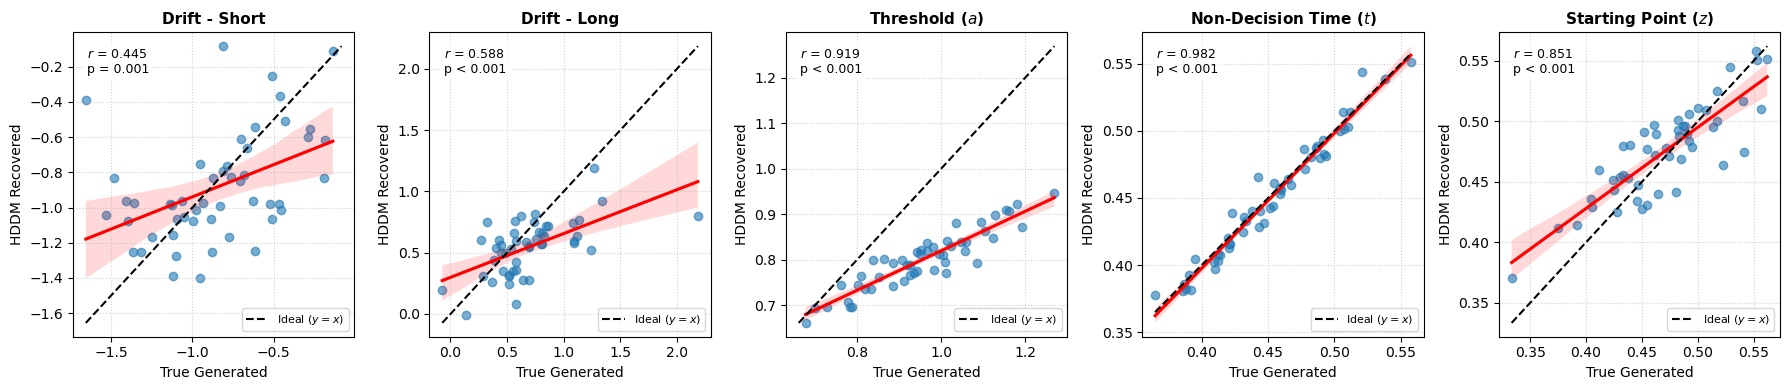

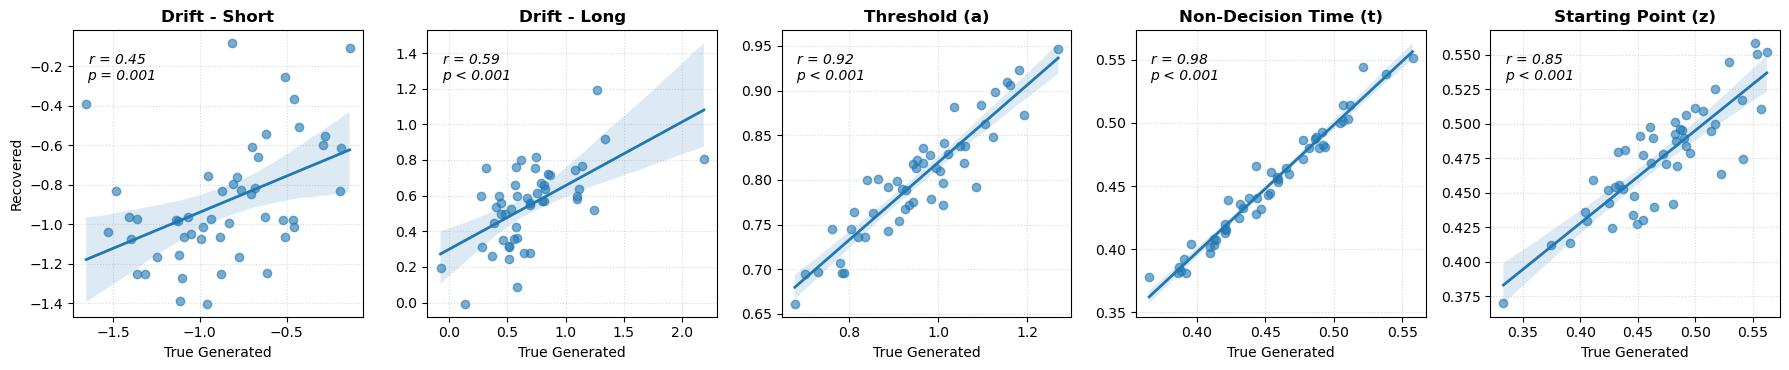

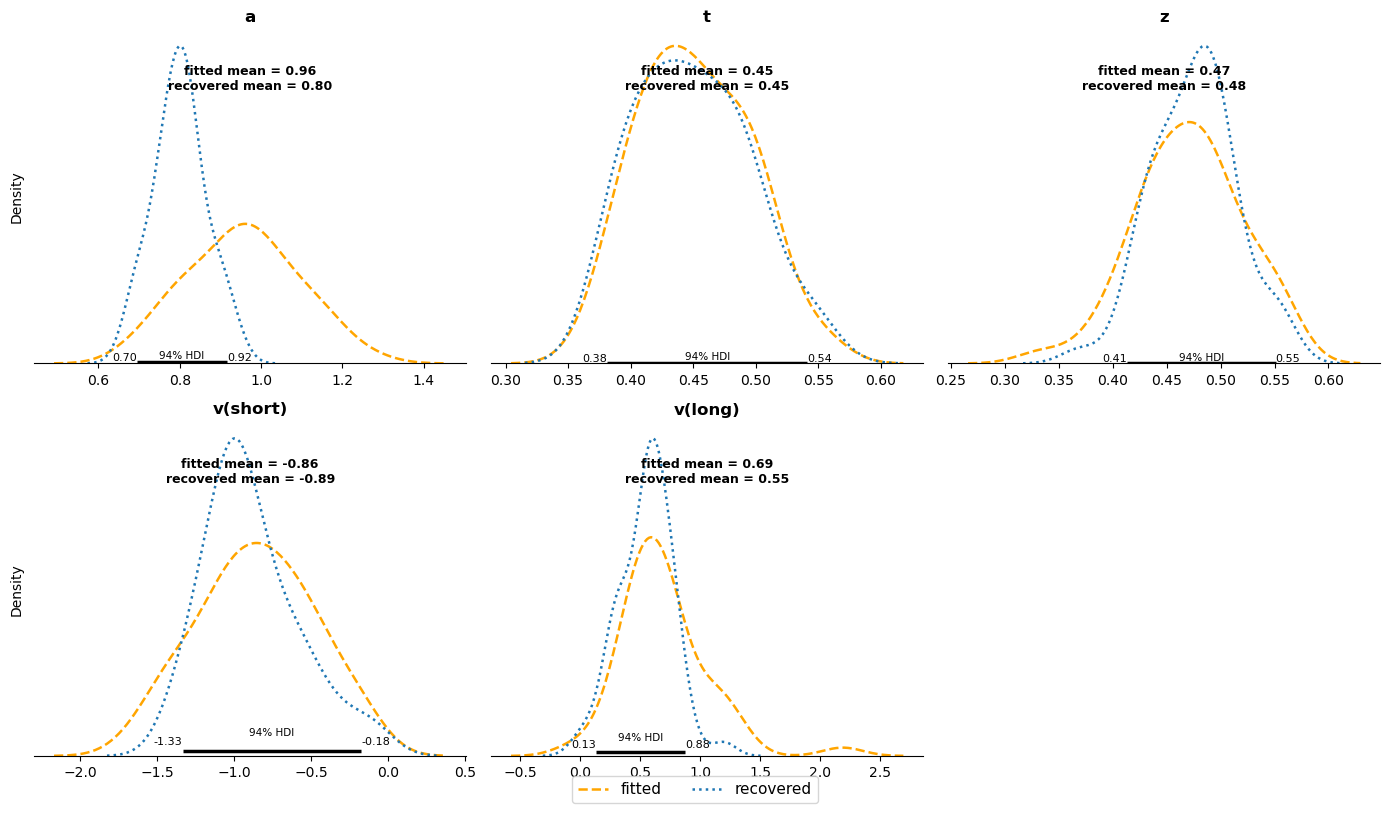

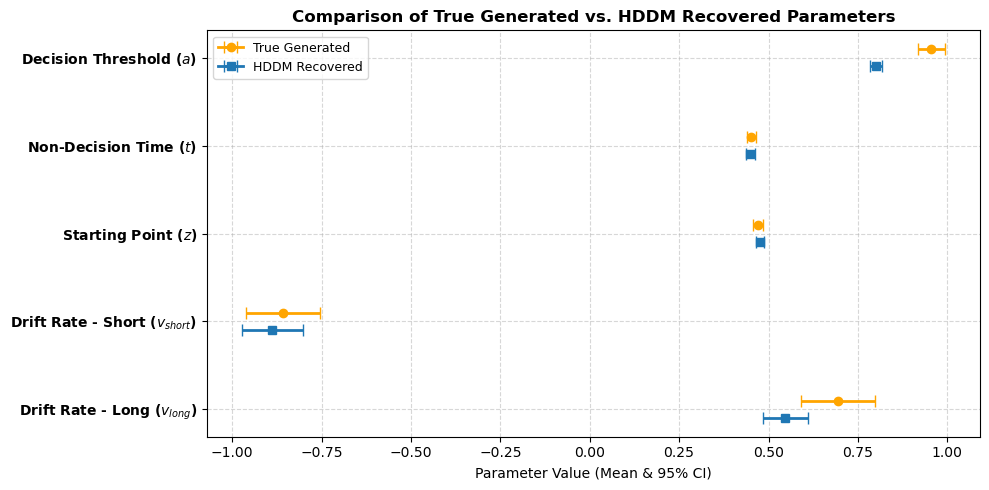

In [17]:
from pathlib import Path
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr

os.makedirs("parameter_recovery_output", exist_ok=True)

# Usar o modelo campeão retornado pela otimização (best_model ou model)
target_model = best_model if "best_model" in globals() else model

# ============================================================
# 1. EXTRAÇÃO ROBUSTA E ALINHADA DOS PARÂMETROS RECUPERADOS
# ============================================================
rec_records = []
subject_ids = df_params["subj_idx"].tolist()

for subj in subject_ids:
    v_short_val, v_long_val, a_val, t_val, z_val = (
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
    )

    for idx_name in target_model.nodes_db.index:
        name_str = str(idx_name)
        subj_pattern = f".{subj}"

        # Mapeamento do Drift Rate (v) por condição de duração
        if subj_pattern in name_str:
            if "v(" in name_str or "v_" in name_str or name_str.startswith("v"):
                if "short" in name_str.lower():
                    v_short_val = target_model.nodes_db.loc[idx_name, "mean"]
                elif "long" in name_str.lower():
                    v_long_val = target_model.nodes_db.loc[idx_name, "mean"]

            # Mapeamento de Threshold (a)
            if name_str == f"a.{subj}" or name_str == f"a_subj.{subj}":
                a_val = target_model.nodes_db.loc[idx_name, "mean"]

            # Mapeamento de Non-Decision Time (t)
            if name_str == f"t.{subj}" or name_str == f"t_subj.{subj}":
                t_val = target_model.nodes_db.loc[idx_name, "mean"]

            # Mapeamento de Starting Point Bias (z)
            if name_str == f"z.{subj}" or name_str == f"z_subj.{subj}":
                z_val = target_model.nodes_db.loc[idx_name, "mean"]

    rec_records.append(
        {
            "subj_idx": subj,
            "v2_rec_short": v_short_val,
            "v2_rec_long": v_long_val,
            "a2_recovered": a_val,
            "t2_recovered": t_val,
            "z2_recovered": z_val,
        }
    )

rec_df = pd.DataFrame(rec_records)
merged_df = pd.merge(df_params, rec_df, on="subj_idx")

merged_df.to_csv(
    "parameter_recovery_output/stage2_recovered_parameters.csv", index=False
)
print(
    "\nParâmetros recuperados guardados com sucesso em 'parameter_recovery_output/stage2_recovered_parameters.csv'!"
)


# ============================================================
# PLOT 1: Gráficos de Densidade (True Generated vs HDDM Recovered)
# ============================================================
parameters_to_check = [
    ("v_true_short", "v2_rec_short", "Drift Rate Stage 2 - Short (v2)"),
    ("v_true_long", "v2_rec_long", "Drift Rate Stage 2 - Long (v2)"),
    ("a_true", "a2_recovered", "Boundary Separation (a)"),
    ("t_true", "t2_recovered", "Non-Decision Time (t)"),
    ("mean_z2_normalized", "z2_recovered", "Starting Point Bias (z)"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
    ax = axes[i]
    if true_col in merged_df.columns and rec_col in merged_df.columns:
        sub_df = (
            merged_df[[true_col, rec_col]]
            .apply(pd.to_numeric, errors="coerce")
            .dropna()
        )

        if len(sub_df) >= 2:
            sns.kdeplot(
                data=sub_df,
                x=true_col,
                ax=ax,
                color="royalblue",
                fill=True,
                alpha=0.3,
                label="True Generated",
            )
            sns.kdeplot(
                data=sub_df,
                x=rec_col,
                ax=ax,
                color="crimson",
                fill=True,
                alpha=0.3,
                label="HDDM Recovered",
            )

            r, p_val = pearsonr(sub_df[true_col], sub_df[rec_col])
            p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

            ax.set_title(
                f"{title}\nr = {r:.3f} ({p_str})", fontsize=11, fontweight="bold"
            )
            ax.set_xlabel("Parameter Value")
            ax.set_ylabel("Density")
            ax.legend(loc="upper right", fontsize=9)
            ax.grid(True, linestyle="--", alpha=0.5)

if len(parameters_to_check) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.suptitle(
    "Two-Stage HDDM: Ground Truth vs. HDDM Recovered Parameter Densities",
    y=1.03,
    fontsize=14,
    weight="bold",
)
plt.savefig(
    "parameter_recovery_output/two_stage_parameter_recovery_density.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ============================================================
# PLOT 2 & 4: Gráficos de Correlação Individual (Scatter + Regressão)
# ============================================================
def regplot_with_corr(x, y, ax, title):
    sub_df = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(sub_df) < 2:
        ax.text(
            0.5,
            0.5,
            "Dados insuficientes",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        return
    r, p_val = pearsonr(sub_df["x"], sub_df["y"])
    p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

    sns.regplot(
        data=sub_df,
        x="x",
        y="y",
        ax=ax,
        scatter_kws={"alpha": 0.6, "color": "#1f77b4"},
        line_kws={"color": "red"},
    )

    min_val = min(sub_df["x"].min(), sub_df["y"].min())
    max_val = max(sub_df["x"].max(), sub_df["y"].max())
    ax.plot(
        [min_val, max_val], [min_val, max_val], "k--", lw=1.5, label="Ideal ($y=x$)"
    )

    text = f"$r$ = {r:.3f}\n{p_str}"
    ax.text(
        0.05,
        0.95,
        text,
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"
        ),
        fontsize=9,
    )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("True Generated")
    ax.set_ylabel("HDDM Recovered")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)


corr_pairs = [
    ("v_true_short", "v2_rec_short", "Drift - Short"),
    ("v_true_long", "v2_rec_long", "Drift - Long"),
    ("a_true", "a2_recovered", "Threshold ($a$)"),
    ("t_true", "t2_recovered", "Non-Decision Time ($t$)"),
    ("mean_z2_normalized", "z2_recovered", "Starting Point ($z$)"),
]

f, axes = plt.subplots(ncols=len(corr_pairs), figsize=(18, 4))
for i, (true_col, rec_col, title) in enumerate(corr_pairs):
    if true_col in merged_df.columns and rec_col in merged_df.columns:
        sub_df = merged_df[[true_col, rec_col]].dropna()
        regplot_with_corr(
            x=sub_df[true_col], y=sub_df[rec_col], ax=axes[i], title=title
        )

plt.tight_layout()
plt.savefig(
    "parameter_recovery_output/two_stage_parameter_recovery_scatter.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# ============================================================
# PLOT: Gráficos de Correlação Individual (Estilo Exato da Imagem)
# ============================================================
def regplot_with_corr_clean(x, y, ax, title):
    sub_df = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(sub_df) < 2:
        ax.text(0.5, 0.5, "Dados insuficientes", ha='center', va='center', transform=ax.transAxes)
        return
    
    r, p_val = pearsonr(sub_df['x'], sub_df['y'])
    p_str = f"p = {p_val:.3f}" if p_val >= 0.001 else "p < 0.001"
    
    # Scatter plot com regressão linear (sem a linha y=x)
    sns.regplot(data=sub_df, x='x', y='y', ax=ax, 
                scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, 
                line_kws={'color': 'tab:blue', 'linewidth': 2})
    
    # Texto limpo no canto superior esquerdo
    text = f"$r$ = {r:.2f}\n{p_str}"
    ax.text(0.05, 0.92, text, transform=ax.transAxes, verticalalignment='top',
            fontsize=10, fontstyle='italic')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("True Generated", fontsize=10)
    ax.set_ylabel("Recovered" if ax == axes[0] else "", fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)

corr_pairs = [
    ("v_true_short", "v2_rec_short", "Drift - Short"),
    ("v_true_long", "v2_rec_long", "Drift - Long"),
    ("a_true", "a2_recovered", "Threshold (a)"),
    ("t_true", "t2_recovered", "Non-Decision Time (t)"),
    ("mean_z2_normalized", "z2_recovered", "Starting Point (z)")
]

fig, axes = plt.subplots(ncols=len(corr_pairs), figsize=(18, 3.8))
for i, (true_col, rec_col, title) in enumerate(corr_pairs):
    if true_col in merged_df.columns and rec_col in merged_df.columns:
        sub_df = merged_df[[true_col, rec_col]].dropna()
        regplot_with_corr_clean(x=sub_df[true_col], y=sub_df[rec_col], ax=axes[i], title=title)

plt.tight_layout()
plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_scatter_clean.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# PLOT 3: Estilo ArviZ (KDE + 94% HDI)
# ============================================================
arviz_params = [
    ("a", "a_true", "a2_recovered"),
    ("t", "t_true", "t2_recovered"),
    ("z", "mean_z2_normalized", "z2_recovered"),
    ("v(short)", "v_true_short", "v2_rec_short"),
    ("v(long)", "v_true_long", "v2_rec_long"),
]

n_params = len(arviz_params)
n_cols = 3
n_rows = (n_params + n_cols - 1) // n_cols

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()
handles, labels = [], []

for i, (param_name, true_col, rec_col) in enumerate(arviz_params):
    ax = axes[i]
    if true_col in merged_df.columns and rec_col in merged_df.columns:
        sub_df = (
            merged_df[[true_col, rec_col]]
            .apply(pd.to_numeric, errors="coerce")
            .dropna()
        )

        if len(sub_df) >= 2:
            vals_true = sub_df[true_col].values
            vals_rec = sub_df[rec_col].values

            mean_true = np.mean(vals_true)
            mean_rec = np.mean(vals_rec)
            hdi_rec = np.percentile(vals_rec, [3, 97])

            sns.kdeplot(
                x=vals_true,
                ax=ax,
                color="orange",
                linestyle="dashed",
                label="fitted",
                lw=1.8,
            )
            sns.kdeplot(
                x=vals_rec,
                ax=ax,
                color="tab:blue",
                linestyle="dotted",
                label="recovered",
                lw=1.8,
            )

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["left"].set_visible(False)
            ax.set_yticks([])
            ax.set_ylabel("Density" if i % n_cols == 0 else "", fontsize=10)
            ax.set_title(param_name, fontsize=12, fontweight="bold")

            ax.text(
                0.5,
                0.82,
                f"fitted mean = {mean_true:.2f}\nrecovered mean = {mean_rec:.2f}",
                transform=ax.transAxes,
                ha="center",
                fontsize=9,
                fontweight="bold",
            )

            ax.hlines(
                y=0.02,
                xmin=hdi_rec[0],
                xmax=hdi_rec[1],
                color="black",
                linewidth=2.5,
            )
            ax.text(hdi_rec[0], 0.05, f"{hdi_rec[0]:.2f}", ha="right", fontsize=8)
            ax.text(hdi_rec[1], 0.05, f"{hdi_rec[1]:.2f}", ha="left", fontsize=8)
            ax.text(np.mean(hdi_rec), 0.09, "94% HDI", ha="center", fontsize=7.5)

            if i == 0:
                handles, labels = ax.get_legend_handles_labels()
            if ax.get_legend():
                ax.get_legend().remove()

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

if handles:
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.02),
        ncol=2,
        fontsize=11,
    )

plt.tight_layout()
plt.savefig(
    "parameter_recovery_output/arviz_style_direct_plot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ============================================================
# PLOT 4: Forest Plot Comparativo (Médias e IC 95%)
# ============================================================
forest_params = [
    ("a", "a_true", "a2_recovered", "Decision Threshold ($a$)"),
    ("t", "t_true", "t2_recovered", "Non-Decision Time ($t$)"),
    ("z", "mean_z2_normalized", "z2_recovered", "Starting Point ($z$)"),
    ("v(short)", "v_true_short", "v2_rec_short", "Drift Rate - Short ($v_{short}$)"),
    ("v(long)", "v_true_long", "v2_rec_long", "Drift Rate - Long ($v_{long}$)"),
]

fig, ax = plt.subplots(figsize=(10, 5))

y_ticks = np.arange(len(forest_params))
labels = [p[3] for p in forest_params]

for idx, (param_name, true_col, rec_col, title) in enumerate(forest_params):
    sub_df = (
        merged_df[[true_col, rec_col]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
    )

    if len(sub_df) >= 2:
        true_mean = sub_df[true_col].mean()
        true_ci = 1.96 * sub_df[true_col].sem()

        rec_mean = sub_df[rec_col].mean()
        rec_ci = 1.96 * sub_df[rec_col].sem()

        ax.errorbar(
            true_mean,
            idx - 0.1,
            xerr=true_ci,
            fmt="o-",
            color="orange",
            label="True Generated" if idx == 0 else "",
            capsize=4,
            lw=2,
        )
        ax.errorbar(
            rec_mean,
            idx + 0.1,
            xerr=rec_ci,
            fmt="s-",
            color="tab:blue",
            label="HDDM Recovered" if idx == 0 else "",
            capsize=4,
            lw=2,
        )

ax.set_yticks(y_ticks)
ax.set_yticklabels(labels, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Parameter Value (Mean & 95% CI)")
ax.set_title(
    "Comparison of True Generated vs. HDDM Recovered Parameters",
    fontsize=12,
    fontweight="bold",
)
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(
    "parameter_recovery_output/direct_forest_plot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Deep Adaptive Optimization Pipeline for Two-Stage HDDM with Staircases

This script implements an automated iterative search and optimization loop (Adaptive Local Zoom) to maximize parameter recovery performance across the Two-Stage Drift-Diffusion Model. 

---

## 🔍 Optimization Strategy

1. **Evolutionary Adaptive Search:** Evaluates multiple candidate parameter sets per generation around a known good starting configuration (`PARAMS` and `PARAMETER_SD`).
2. **Adaptive Radius Shrinking (`search_scale`):** Dynamically tightens the search space radius across generations (`max(0.2, 1.0 - gen * 0.15)`) to fine-tune parameter estimates locally.
3. **Parallel MCMC Fitness Evaluation:** Runs parallel simulation, staircase generation, and HDDM fitting (`N_CHAINS=2`, `MCMC_SAMPLES=2500`) for each candidate to calculate mean Pearson correlation ($r$) recovery scores across all core DDM parameters ($v_{\text{short}}, v_{\text{long}}, a, t, z$).
4. **Global Record Tracking:** Automatically updates and logs the global optimal parameters whenever a new higher mean $r$-score record is achieved.

---

## 🚀 Key Configurations & Outputs

* **Seed & Scale:** Configured with fixed reproducibility seeds (`SEED = 20261023`) and evaluated across $N = 50$ participants per candidate.
* **Output Directory:** All intermediate trial details, temporary database chains, and best configuration logs are directed to `parameter_optimization_deep_output/`.
* **Goal:** Maximize statistical power and refine group-level hyper-parameters prior to full empirical fitting.

In [115]:
from pathlib import Path
import os
import ast
import numpy as np
import pandas as pd
import hddm
from joblib import Parallel, delayed
from scipy.stats import pearsonr

# ============================================================
# CONFIGURAÇÃO GLOBAL DE OTIMIZAÇÃO PROFUNDA
# ============================================================
SEED = 20261023
N_PARTICIPANTS = 50       # Aumentado para dar mais poder estatístico aos drifts
N_CHAINS = 2
MCMC_SAMPLES = 2500       # Amostras maiores para maior precisão nas posteriores
MCMC_BURN = 600

CONDITIONS_FILE = Path("condicoes_teste14.csv")
OUTPUT_DIR = Path("parameter_optimization_deep_output")
OUTPUT_DIR.mkdir(exist_ok=True)

if not CONDITIONS_FILE.exists():
    raise FileNotFoundError(f"Arquivo {CONDITIONS_FILE} não encontrado.")

conditions_df = pd.read_csv(CONDITIONS_FILE, sep=";")
staircase_conditions = []
for _, row in conditions_df.iterrows():
    step_sizes_raw = row["stepSizes"]
    if isinstance(step_sizes_raw, str):
        try:
            step_sizes = ast.literal_eval(step_sizes_raw)
        except:
            step_sizes = [float(x.strip()) for x in step_sizes_raw.replace("[", "").replace("]", "").split(",")]
    else:
        step_sizes = list(step_sizes_raw)
    
    staircase_conditions.append({
        "label": str(row["label"]),
        "start": float(row["startVal"]),
        "minimum": float(row["minVal"]),
        "maximum": float(row["maxVal"]),
        "n_up": int(row["nUp"]),
        "n_down": int(row["nDown"]),
        "n_reversals": int(row["nReversals"]),
        "step_sizes": [abs(s) for s in step_sizes]
    })

def initialize_staircase(condition):
    return {
        "condition": condition,
        "duration": float(condition["start"]),
        "previous_direction": None,
        "consecutive_long": 0,
        "consecutive_short": 0,
        "reversal_count": 0,
        "trial_in_staircase": 0,
        "active": True,
    }

# ============================================================
# FUNÇÃO DE SIMULAÇÃO E FIT DO HDDM
# ============================================================
def simulate_and_fit(candidate_params, candidate_sd, subj_params_seed):
    np.random.seed(subj_params_seed)
    
    participant_parameters = {}
    for subj in range(1, N_PARTICIPANTS + 1):
        participant_parameters[subj] = {
            "a": max(0.1, np.random.normal(candidate_params["a"], candidate_sd["a"])),
            "t": max(0.05, np.random.normal(candidate_params["t"], candidate_sd["t"])),
            "v1": max(0.0, np.random.normal(candidate_params["v1"], candidate_sd["v1"])),
            "k": max(0.1, np.random.normal(candidate_params["k"], candidate_sd["k"]))
        }

    all_trials = []
    subject_true_metrics = []

    for subj, params in participant_parameters.items():
        staircases = [initialize_staircase(c) for c in staircase_conditions]
        global_trial = 0
        round_number = 0
        tracking = {"short_v2": [], "long_v2": [], "z2_trials": []}

        while any(s["active"] for s in staircases):
            ordered = staircases if round_number % 2 == 0 else staircases[::-1]
            for st in ordered:
                if not st["active"]: continue
                global_trial += 1
                
                condition = st["condition"]
                duration = st["duration"]
                subj_a, subj_t, subj_v1, subj_k = params["a"], params["t"], params["v1"], params["k"]
                
                target, gamma = 2.0, 0.2
                I_current = (subj_a / target) * subj_v1
                drift = I_current - (gamma * I_current)
                dcoeff = np.sqrt(I_current + (I_current * gamma)) * 0.1

                current_time, stage1_elapsed, x1 = 0.0, 0.0, 0.0
                terminated_in_stage1 = False
                while stage1_elapsed < duration:
                    x1 += drift * 0.001 + np.sqrt(0.001) * np.sqrt(drift) * dcoeff * np.random.normal(0, 1)
                    current_time += 0.001
                    stage1_elapsed += 0.001
                    if x1 < 0: x1 = -x1
                    if x1 >= subj_a:
                        terminated_in_stage1 = True
                        break

                if terminated_in_stage1:
                    response, rt = 1, subj_t
                    x_offset = x1
                    drift2 = None
                else:
                    x_at_offset = x1
                    x2 = x_at_offset
                    stage2_elapsed = 0.0
                    hit = None
                    while current_time < 5.0:
                        v_stage2 = subj_k * (x2 - subj_a / 2.0)
                        x2 += v_stage2 * 0.001 + np.sqrt(0.001) * 1.0 * np.random.normal(0, 1)
                        current_time += 0.001
                        stage2_elapsed += 0.001
                        if x2 >= subj_a:
                            hit, rt = "upper", stage2_elapsed + subj_t
                            break
                        elif x2 <= 0.0:
                            hit, rt = "lower", stage2_elapsed + subj_t
                            break
                    response = 1 if hit == "upper" else (0 if hit == "lower" else int(x2 >= subj_a / 2.0))
                    if hit is None: rt = 5.0 + subj_t
                    x_offset = x_at_offset
                    drift2 = subj_k * (x_offset - subj_a / 2.0)

                tracking["z2_trials"].append(x_offset)
                if drift2 is not None:
                    if x_offset < (subj_a / 2.0): tracking["short_v2"].append(drift2)
                    else: tracking["long_v2"].append(drift2)

                resp_val = response
                n_up = condition["n_up"]
                n_down = condition["n_down"]
                step_sizes = condition["step_sizes"]
                minimum = condition["minimum"]
                maximum = condition["maximum"]
                n_reversals_target = condition["n_reversals"]

                direction = None
                if st["reversal_count"] == 0:
                    direction = -1 if resp_val == 1 else 1
                else:
                    if resp_val == 1: st["consecutive_long"] += 1; st["consecutive_short"] = 0
                    else: st["consecutive_short"] += 1; st["consecutive_long"] = 0
                    if st["consecutive_long"] >= n_up: direction = -1
                    elif st["consecutive_short"] >= n_down: direction = 1

                if direction is not None:
                    st["consecutive_long"] = st["consecutive_short"] = 0
                    prev_dir = st["previous_direction"]
                    if prev_dir is not None and direction != prev_dir: st["reversal_count"] += 1
                    if st["reversal_count"] >= n_reversals_target: st["active"] = False
                    st["previous_direction"] = direction
                    step = float(step_sizes[min(st["reversal_count"], len(step_sizes)-1)])
                    st["duration"] = float(np.clip(duration + direction * step, minimum, maximum))

                all_trials.append({
                    "subj_idx": subj, "trial": global_trial, "duration": float(duration),
                    "rt": float(rt), "response": int(resp_val), "staircase": condition["label"],
                    "x_offset": x_offset, "drift2": drift2
                })
            round_number += 1

        subject_true_metrics.append({
            'subj_idx': subj,
            'v_true_short': np.mean(tracking["short_v2"]) if tracking["short_v2"] else np.nan,
            'v_true_long': np.mean(tracking["long_v2"]) if tracking["long_v2"] else np.nan,
            'a_true': params["a"],
            'z2_true': np.mean(tracking["z2_trials"]) if tracking["z2_trials"] else np.nan,
            'mean_z2_normalized': (np.mean(tracking["z2_trials"]) / params["a"]) if tracking["z2_trials"] else np.nan,
            't_true': params["t"]
        })

    df_data = pd.DataFrame(all_trials)
    df_params = pd.DataFrame(subject_true_metrics)
    
    df_data['duration_class'] = np.where(df_data['duration'] < df_data['duration'].mean(), 'short', 'long')
    df_data = hddm.utils.flip_errors(df_data)

    def fit_chain(chain_idx):
        np.random.seed(100 + chain_idx)
        m = hddm.HDDM(df_data, include=['v', 'a', 't', 'z'], informative=True,
                      depends_on={'v': 'duration_class'}, p_outlier=0.05, is_group_model=True)
        m.find_starting_values()
        m.sample(MCMC_SAMPLES, burn=MCMC_BURN, dbname=f'temp_chain_{chain_idx}.db', db='pickle')
        return m

    models = Parallel(n_jobs=N_CHAINS)(delayed(fit_chain)(i) for i in range(N_CHAINS))
    best_model = min(models, key=lambda x: x.dic)

    rec_v_short, rec_v_long, rec_a, rec_t, rec_z = [], [], [], [], []
    for subj in df_params["subj_idx"].tolist():
        v_short_val, v_long_val, a_val, t_val, z_val = np.nan, np.nan, np.nan, np.nan, np.nan
        for idx_name in best_model.nodes_db.index:
            name_str = str(idx_name)
            if 'v' in name_str and f".{subj}" in name_str:
                if 'short' in name_str.lower(): v_short_val = best_model.nodes_db.loc[idx_name, "mean"]
                elif 'long' in name_str.lower(): v_long_val = best_model.nodes_db.loc[idx_name, "mean"]
            if name_str == f"a_subj.{subj}" or name_str == f"a.{subj}": a_val = best_model.nodes_db.loc[idx_name, "mean"]
            if name_str == f"t_subj.{subj}" or name_str == f"t.{subj}": t_val = best_model.nodes_db.loc[idx_name, "mean"]
            if name_str == f"z_subj.{subj}" or name_str == f"z.{subj}": z_val = best_model.nodes_db.loc[idx_name, "mean"]

        rec_v_short.append(v_short_val); rec_v_long.append(v_long_val)
        rec_a.append(a_val); rec_t.append(t_val); rec_z.append(z_val)

    merged = df_params.copy()
    merged["v2_rec_short"], merged["v2_rec_long"], merged["a2_rec"], merged["t2_rec"], merged["z2_rec"] = \
        rec_v_short, rec_v_long, rec_a, rec_t, rec_z

    corrs = []
    for true_c, rec_c in [('v_true_short', 'v2_rec_short'), ('v_true_long', 'v2_rec_long'), 
                          ('a_true', 'a2_rec'), ('t_true', 't2_rec'), ('mean_z2_normalized', 'z2_rec')]:
        sub = merged[[true_c, rec_c]].dropna()
        if len(sub) > 5:
            r, _ = pearsonr(sub[true_c], sub[rec_c])
            corrs.append(r if not np.isnan(r) else 0.0)
        else:
            corrs.append(0.0)

    mean_r = np.mean(corrs)
    print(f"-> Candidato testado | Média r de Pearson: {mean_r:.3f} | Detalhes [v_s, v_l, a, t, z]: {[round(c, 3) for c in corrs]}")
    return mean_r, candidate_params, candidate_sd

if __name__ == "__main__":
    print("\n[Iniciando Otimização Profunda com Refinamento Adaptativo Local]...")
    
    # Partimos do melhor ponto encontrado anteriormente
    current_best_params = {'a': 0.915, 't': 0.431, 'v1': 0.967, 'k': 5.195}
    current_best_sd = {'a': 0.126, 't': 0.080, 'v1': 0.171, 'k': 0.145}
    best_score = 0.671

    n_generations = 5
    candidates_per_gen = 4

    for gen in range(n_generations):
        print(f"\n================ GERAÇÃO {gen + 1} de {n_generations} ================")
        
        # O raio de busca encolhe a cada geração (Zoom Adaptativo Local)
        search_scale = max(0.2, 1.0 - (gen * 0.15))
        
        candidates = []
        for _ in range(candidates_per_gen):
            p = {
                "a": np.clip(np.random.normal(current_best_params["a"], 0.08 * search_scale), 0.6, 1.3),
                "t": np.clip(np.random.normal(current_best_params["t"], 0.04 * search_scale), 0.2, 0.6),
                "v1": np.clip(np.random.normal(current_best_params["v1"], 0.15 * search_scale), 0.5, 2.0),
                "k": np.clip(np.random.normal(current_best_params["k"], 0.5 * search_scale), 2.0, 8.0)
            }
            sd = {
                "a": np.clip(np.random.normal(current_best_sd["a"], 0.02 * search_scale), 0.03, 0.2),
                "t": np.clip(np.random.normal(current_best_sd["t"], 0.01 * search_scale), 0.01, 0.15),
                "v1": np.clip(np.random.normal(current_best_sd["v1"], 0.03 * search_scale), 0.05, 0.3),
                "k": np.clip(np.random.normal(current_best_sd["k"], 0.03 * search_scale), 0.02, 0.3)
            }
            candidates.append((p, sd))

        results = []
        for idx, (p, sd) in enumerate(candidates):
            print(f"Testando candidato {idx+1}/{candidates_per_gen} (escala zoom: {search_scale:.2f})...")
            try:
                score, params_val, sd_val = simulate_and_fit(p, sd, subj_params_seed=3000 + gen*10 + idx)
                results.append((score, params_val, sd_val))
            except Exception as e:
                print(f"Erro no candidato {idx+1}: {e}")

        if results:
            gen_best_score, gen_best_p, gen_best_sd = max(results, key=lambda x: x[0])
            print(f">> Melhor da Geração {gen+1}: r médio = {gen_best_score:.3f}")
            
            if gen_best_score > best_score:
                best_score = gen_best_score
                current_best_params = gen_best_p
                current_best_sd = gen_best_sd
                print("🌟 Novo recorde global absoluto atingido!")

    print("\n========================================================")
    print(f"OTIMIZAÇÃO PROFUNDA CONCLUÍDA! Melhor r Médio: {best_score:.3f}")
    print("Melhores PARAMS ótimos:", current_best_params)
    print("Melhores PARAMETER_SD ótimos:", current_best_sd)
    print("========================================================")


[Iniciando Otimização Profunda com Refinamento Adaptativo Local]...

================ GERAÇÃO 1 de 5 ================
Testando candidato 1/4 (escala zoom: 1.00)...


/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)
/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)


[-----------------76%--------          ] 381 of 500 complete in 22.9 sec
[-----------------78%---------         ] 390 of 500 complete in 23.5 sec
[-----------------79%----------        ] 399 of 500 complete in 24.0 sec
[-----------------81%----------        ] 407 of 500 complete in 24.6 sec
[-----------------83%-----------       ] 415 of 500 complete in 25.1 sec
[-----------------84%------------      ] 423 of 500 complete in 25.6 sec
[-----------------86%------------      ] 431 of 500 complete in 26.1 sec
[-----------------87%-------------     ] 439 of 500 complete in 26.7 sec
[-----------------89%--------------    ] 448 of 500 complete in 27.2 sec
[-----------------91%--------------    ] 456 of 500 complete in 27.7 sec
[-----------------92%---------------   ] 464 of 500 complete in 28.3 sec
[-----------------94%---------------   ] 473 of 500 complete in 28.8 sec
[-----------------96%----------------  ] 482 of 500 complete in 29.4 sec
[-----------------98%----------------- ] 491 of 500

[---              10%                  ] 256 of 2500 complete in 19.9 sec
[---              10%                  ] 263 of 2500 complete in 20.4 sec
[----             10%                  ] 270 of 2500 complete in 20.9 sec
[----             11%                  ] 277 of 2500 complete in 21.5 sec
[----             11%                  ] 284 of 2500 complete in 22.0 sec
[----             11%                  ] 291 of 2500 complete in 22.5 sec
[----             11%                  ] 298 of 2500 complete in 23.0 sec
[----             12%                  ] 305 of 2500 complete in 23.5 sec
[----             12%                  ] 312 of 2500 complete in 24.0 sec
[----             12%                  ] 319 of 2500 complete in 24.6 sec
[----             13%                  ] 326 of 2500 complete in 25.1 sec
[-----            13%                  ] 333 of 2500 complete in 25.7 sec
[-----            13%                  ] 340 of 2500 complete in 26.2 sec
[-----            13%                 

[---------------  40%                  ] 1020 of 2500 complete in 78.0 sec
[---------------  41%                  ] 1027 of 2500 complete in 78.5 sec
[---------------  41%                  ] 1034 of 2500 complete in 79.1 sec
[---------------  41%                  ] 1041 of 2500 complete in 79.6 sec
[---------------  41%                  ] 1048 of 2500 complete in 80.2 sec
[---------------- 42%                  ] 1055 of 2500 complete in 80.7 sec
[---------------- 42%                  ] 1062 of 2500 complete in 81.3 sec
[---------------- 42%                  ] 1069 of 2500 complete in 81.8 sec
[---------------- 43%                  ] 1076 of 2500 complete in 82.3 sec
[---------------- 43%                  ] 1083 of 2500 complete in 82.8 sec
[---------------- 43%                  ] 1090 of 2500 complete in 83.4 sec
[---------------- 43%                  ] 1097 of 2500 complete in 83.9 sec
[---------------- 44%                  ] 1104 of 2500 complete in 84.4 sec
[---------------- 44%    

-> Candidato testado | Média r de Pearson: 0.684 | Detalhes [v_s, v_l, a, t, z]: [-0.026, 0.666, 0.934, 0.997, 0.849]
Testando candidato 2/4 (escala zoom: 1.00)...


... (97 outputs left out)

[-----------------91%--------------    ] 2291 of 2500 complete in 176.4 sec
[-----------------91%--------------    ] 2298 of 2500 complete in 176.9 sec
[-----------------92%---------------   ] 2305 of 2500 complete in 177.4 sec
[-----------------92%---------------   ] 2312 of 2500 complete in 178.0 sec
[-----------------92%---------------   ] 2319 of 2500 complete in 178.5 sec
[-----------------93%---------------   ] 2326 of 2500 complete in 179.1 sec
[-----------------93%---------------   ] 2333 of 2500 complete in 179.6 sec
[-----------------93%---------------   ] 2340 of 2500 complete in 180.2 sec
[-----------------93%---------------   ] 2347 of 2500 complete in 180.7 sec
[-----------------94%---------------   ] 2354 of 2500 complete in 181.3 sec
[-----------------94%---------------   ] 2361 of 2500 complete in 181.8 sec
[-----------------94%---------------   ] 2368 of 2500 complete in 182.3 sec
[-----------------95%----------------  ] 2375 of 2500 complete in 182.9 sec
[-----------

[--------         23%                  ] 583 of 2500 complete in 42.2 sec
[--------         23%                  ] 591 of 2500 complete in 42.8 sec
[---------        23%                  ] 599 of 2500 complete in 43.4 sec
[---------        24%                  ] 607 of 2500 complete in 43.9 sec
[---------        24%                  ] 614 of 2500 complete in 44.4 sec
[---------        24%                  ] 621 of 2500 complete in 44.9 sec
[---------        25%                  ] 628 of 2500 complete in 45.4 sec
[---------        25%                  ] 635 of 2500 complete in 45.9 sec
[---------        25%                  ] 643 of 2500 complete in 46.5 sec
[---------        26%                  ] 650 of 2500 complete in 47.0 sec
[---------        26%                  ] 657 of 2500 complete in 47.6 sec
[----------       26%                  ] 664 of 2500 complete in 48.1 sec
[----------       26%                  ] 671 of 2500 complete in 48.6 sec
[----------       27%                 

[-----------------54%                  ] 1372 of 2500 complete in 100.5 sec
[-----------------55%                  ] 1379 of 2500 complete in 101.0 sec
[-----------------55%-                 ] 1386 of 2500 complete in 101.5 sec
[-----------------55%-                 ] 1393 of 2500 complete in 102.0 sec
[-----------------56%-                 ] 1400 of 2500 complete in 102.5 sec
[-----------------56%-                 ] 1407 of 2500 complete in 103.0 sec
[-----------------56%-                 ] 1414 of 2500 complete in 103.5 sec
[-----------------56%-                 ] 1421 of 2500 complete in 104.1 sec
[-----------------57%-                 ] 1428 of 2500 complete in 104.6 sec
[-----------------57%-                 ] 1435 of 2500 complete in 105.1 sec
[-----------------57%-                 ] 1443 of 2500 complete in 105.7 sec
[-----------------58%--                ] 1450 of 2500 complete in 106.2 sec
[-----------------58%--                ] 1457 of 2500 complete in 106.7 sec
[-----------

-> Candidato testado | Média r de Pearson: 0.599 | Detalhes [v_s, v_l, a, t, z]: [-0.108, 0.388, 0.843, 0.995, 0.878]
>> Melhor da Geração 5: r médio = 0.681

OTIMIZAÇÃO PROFUNDA CONCLUÍDA! Melhor r Médio: 0.685
Melhores PARAMS ótimos: {'a': 0.9596969746426115, 't': 0.44935217290223706, 'v1': 0.8694589198061199, 'k': 4.886499257198901}
Melhores PARAMETER_SD ótimos: {'a': 0.16771087002597207, 't': 0.04944977258126838, 'v1': 0.16363628745812564, 'k': 0.11588160427220655}
